# Практическое занятие №1. Ансамблиевые методы машинного обучения

## Случайный лес (Random Forest) на прогнозе спроса велосипедов

**Дисциплина:** Методы машинного обучения
**Кафедра:** Интеллектуальных информационных систем и кибербезопасности
**ВУЗ:** АНО ВО РОСНОУ
**Преподаватель:** Марков Артем Алексеевич
**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Служба проката велосипедов закупает велосипеды под конкретные часы и дни. Если
не знать, сколько людей придёт за велосипедом **в час 18 рабочего дня**, дежурный
диспетчер не сможет вовремя отправить машину с велосипедами на станцию — и станция
останется пустой в самый загруженный час.

Значит, задача формулируется так: **по часовым данным за два года восстановить
число аренд `count` в конкретный час**. Это задача **регрессии** — ответ
непрерывный (целое число аренд), а не один из нескольких классов.

Почему именно случайный лес:

* данные **табличные**, смешанные — есть «часы» (числа), «сезон» (номер),
  «погода» (категория), «температура» (доля от единицы). Дерево решений
  умеет работать с таким напрямую, без кодирования и нормализации;
* спрос на велосипеды зависит от **взаимодействия** факторов: не «час 18
  всегда пик», а «час 18 **рабочего** дня, **если** не дождь». Такие правила
  «если — то» дерево записывает естественно, а линейная модель — нет;
* лес из hundreds деревьев **усредняет** их ответы и за счёт этого гораздо
  устойчивее к переобучению, чем одно-единственное дерево;
* `feature_importances_` у леса считается «из коробки» — а в этой работе важно
  не только предсказать, но и **объяснить**, что именно влияет на спрос.

Работа построена по шагам: данные → проверка и очистка → разведочный анализ →
подготовка → модель → оценка → выводы.


In [1]:
# Ячейка 1 — зависимости.
#
# В Google Colab этот стек уже установлен, и команда ничего не скачивает.
# Локально она ставит недостающее, поэтому один и тот же ноутбук работает
# и в облаке, и на машине. Версии не фиксируем: pip подберёт совместимые.
%pip install -q torch torchvision numpy pandas scikit-learn matplotlib seaborn

# Проверяем, что всё действительно доступно, — иначе ошибка всплывёт
# не в этой ячейке, а где-нибудь в середине обучения.
import importlib

for _package in ("torch", "torchvision", "numpy", "pandas", "sklearn",
                 "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.


torch        2.14.0+cpu


torchvision  0.29.1+cpu
numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты собраны в одной ячейке в самом верху файла — так их удобнее
# просматривать, и ниже по ноутбуку не остаётся «внезапно» появляющихся
# библиотек.

# Загрузка данных прямо из архива: сам датасет не хранится в репозитории, а скачивается
# с официальной страницы UCI — это честнее, чем класть копию csv рядом с ноутбуком.
import io
import urllib.request
import zipfile

# Работа с таблицей: чтение csv, пропуски, группировка, сводные таблицы.
import pandas as pd

# Численные операции: тригонометрия для кодирования времени суток, разности, средние.
import numpy as np

# Графики. pyplot — базовые полотна и оси, seaborn — аккуратные heatmap, boxplot и barplot.
import matplotlib.pyplot as plt
import seaborn as sns

# Модель: случайный лес для регрессии.
from sklearn.ensemble import RandomForestRegressor

# Базовая линия: предсказание среднего значения целевой переменной.
from sklearn.dummy import DummyRegressor

# Разделение выборки и фиксация генератора случайных чисел.
from sklearn.model_selection import train_test_split

# Метрики регрессии. MAE — средняя абсолютная ошибка в «штуках велосипедов»,
# RMSE — она же, но сильнее штрафует за редкие сильные промахи,
# R2 — доля объяснённой дисперсии относительно предсказания среднего.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
# Воспроизводимость: фиксируем генератор случайных чисел, иначе каждый запуск
# ноутбука давал бы немного другие метрики — а случайный лес зависит от случайного
# выбора признаков при построении каждого дерева.
SEED = 42
np.random.seed(SEED)

# Параметры случайного леса, зафиксированные для всей работы.
# n_estimators=200 — число деревьев: больше деревьев = стабильнее усреднение,
#   но заметно медленнее; 200 — разумный компромисс для 17 тысяч строк.
# n_jobs=-1 — обучать деревья параллельно на всех ядрах процессора.
# random_state=SEED — фиксированное зерно генератора.
N_ESTIMATORS = 200
N_JOBS = -1

# Единый стиль оформления всех графиков ноутбука.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)

print(f"Зерно генератора: {SEED}, деревьев в лесу: {N_ESTIMATORS}")

Зерно генератора: 42, деревьев в лесу: 200


## 1. Данные

### 1.1 Какой датасет и почему он

**Bike Sharing Demand** (UCI Machine Learning Repository) — открытый набор данных
оператора велопроката из Вашингтона (США). В архиве два файла: `day.csv`
(731 дневная запись) и `hour.csv` (17 379 почасовых записей). Мы берём **`hour.csv`**:
 hourly-гранулярность здесь принципиальна, потому что предсказывается спрос
**в конкретный час**, а разница между 8 утра и 18 вечера — это и есть объект прогноза.

Период: **1 января 2011 — 31 декабря 2012**, то есть ровно два полных года.
Два года — важно: внутри каждого года повторяется один и тот же годовой рисунок
(зимой велосипеды почти не берут, летом берут много), и без второго года
модель приняла бы зиму за норму.

| Столбец | Тип | Что означает |
|---|---|---|
| `instant` | числовой | сквозной номер записи, порядок появления данных |
| `dteday` | дата | дата наблюдения в формате `ГГГГ-ММ-ДД` |
| `season` | категориальный | сезон: 1 — зима, 2 — весна, 3 — лето, 4 — осень |
| `yr` | категориальный | год: 0 — 2011, 1 — 2012 |
| `mnth` | категориальный | месяц: 1…12 |
| `hr` | категориальный | час суток: 0…23 |
| `holiday` | бинарный | 1 — официальный праздник, 0 — обычный день |
| `weekday` | категориальный | день недели: 0 — воскресенье … 6 — суббота |
| `workingday` | бинарный | 1 — будний рабочий день, 0 — выходной или праздник |
| `weathersit` | категориальный | погода: 1 — ясно, 2 — туман, 3 — дождь/снег, 4 — сильная буря |
| `temp` | доля от 1 | температура воздуха, нормированная: 0.0 → 0 °C, 1.0 → 100 % от максимума шкалы |
| `atemp` | доля от 1 | ощущаемая температура, нормирована так же |
| `hum` | доля от 1 | относительная влажность: 0.0…1.0 |
| `windspeed` | доля от 1 | скорость ветра, нормированная: 0.0…1.0 |
| `casual` | числовой | аренды неregistered-пользователями |
| `registered` | числовой | аренды зарегистрированными пользователями |
| `count` (**cnt**) | числовой | **целевая переменная**: общее число аренд за час |

### 1.2 Почему `casual` и `registered` нельзя отдавать модели

Это главная содержательная тонкость всего датасета, поэтому она вынесена
в отдельный пункт.

В исходном csv целевая колонка называется `cnt`, а рядом лежат `casual`
и `registered`. Между ними выполняется **точное тождество**:

```
count = casual + registered
```

То есть `casual` и `registered` — это не «дополнительные признаки о погоде
и времени», а **арифметическое разложение самой целевой переменной** на две
части. Использовать их как входы модели — это **утечка данных** (data leakage):
пользователь сдаёт части ответа рядом с самим ответом.

Последствия предсказуемы и катастрофичны: дерево за два-три разбиения находит
`registered` (это ~70–80 % спроса) и даёт почти идеальную точность — **R² ≈ 1.0**.
Метрика при этом ничего не значит: на реальных данных, где `registered` не известен
заранее (его узнают только после аренды), такая модель бесполезна.

Поэтому в работе `casual` и `registered` **удаляются до обучения безоговорочно**,
и ниже это удаление показано кодом — чтобы было видно, что решение осознанное.

In [4]:
# Архив лежит на официальной странице репозитория UCI. Открываем поток с таймаутом,
# чтобы при отсутствии сети ошибка была понятным сообщением, а не «зависанием».
ARCHIVE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00275/Bike-Sharing-Dataset.zip"

with urllib.request.urlopen(ARCHIVE_URL, timeout=120) as response:
    archive_bytes = response.read()

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    print("Файлы в архиве:", archive.namelist())
    # hour.csv, а не day.csv: в нём 17 379 почасовых строк — нужная нам гранулярность.
    raw = pd.read_csv(archive.open("hour.csv"))

print(f"\nРазмер hour.csv: {raw.shape[0]} строк, {raw.shape[1]} столбцов")
print("Период наблюдений:", raw["dteday"].min(), "—", raw["dteday"].max())
display(raw.head())

Файлы в архиве: ['Readme.txt', 'day.csv', 'hour.csv']

Размер hour.csv: 17379 строк, 17 столбцов
Период наблюдений: 2011-01-01 — 2012-12-31


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Строк, где casual + registered != cnt: 0
Максимальное расхождение: 0


,канал,всего аренд,"доля, %"
0,casual,620017,18.8
1,registered,2672662,81.2


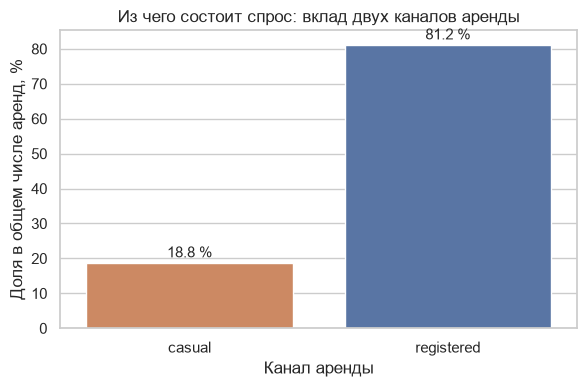

In [5]:
# Проверяем тождество count = casual + registered, о котором шла речь выше.
# Именно этот факт и означает утечку: сумма двух «признаков» равна ответу.
decomposition_error = (raw["casual"] + raw["registered"] - raw["cnt"]).abs()
print(f"Строк, где casual + registered != cnt: {int((decomposition_error > 0).sum())}")
print(f"Максимальное расхождение: {decomposition_error.max()}")

# Наглядно: доля каждой части в общем спросе. Видно, что registered — это основная
# часть спроса, поэтому модель, получив его «бесплатно», почти решает задачу.
parts = pd.DataFrame({
    "канал": ["casual", "registered"],
    "всего аренд": [int(raw["casual"].sum()), int(raw["registered"].sum())],
})
parts["доля, %"] = (100 * parts["всего аренд"] / parts["всего аренд"].sum()).round(1)
display(parts)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=parts, x="канал", y="доля, %", hue="канал", ax=ax,
            palette=["#DD8452", "#4C72B0"], legend=False)
ax.set_title("Из чего состоит спрос: вклад двух каналов аренды")
ax.set_xlabel("Канал аренды")
ax.set_ylabel("Доля в общем числе аренд, %")
for index, value in enumerate(parts["доля, %"]):
    ax.text(index, value + 1.5, f"{value} %", ha="center")
plt.tight_layout()
plt.show()

In [6]:
# Удаляем утечку и служебные столбцы.
# instant — просто сквозной номер строки, никакой новой информации в нём нет.
# dteday здесь оставляем: из него ниже выведутся год, месяц и день недели.
# cnt переименовываем в count — так целевая переменная называется в постановке задачи.
df = raw.drop(columns=["casual", "registered", "instant"]).rename(columns={"cnt": "count"})

TARGET = "count"
print(f"Строк после удаления утечки: {len(df)}, столбцов: {df.shape[1]}")
print("Столбцы в работе:", list(df.columns))
display(df.head())

Строк после удаления утечки: 17379, столбцов: 14
Столбцы в работе: ['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'count']


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,count
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


---

## 2. Проверка и очистка данных

Очистку нужно проводить **вслепую**: даже если данные выглядят чистыми, сам код
проверок обязателен — иначе неизвестно, чистые они или просто ещё не проверены.
Ниже пять проверок: дубликаты, пропуски, диапазоны, логическая согласованность
и выбросы.

In [7]:
# 2.1 Дубликаты.
# Полные дубликаты — две одинаковые строки целиком. Отдельно проверяем дубликаты
# по «логическому ключу» даты и часа: именно они означали бы, что один и тот же час
# учтён дважды, и это уже настоящая ошибка данных, а не повтор csv-строки.
full_duplicates = int(df.duplicated().sum())
key_duplicates = int(df.duplicated(subset=["dteday", "hr"]).sum())

print(f"Полностью повторяющихся строк: {full_duplicates}")
print(f"Повторов по паре (дата, час):   {key_duplicates}")
print("Вывод: часовые отметки уникальны, удалять нечего." if key_duplicates == 0
      else f"Вывод: повторов по паре (дата, час) — {key_duplicates}, они удаляются ниже.")

if key_duplicates:
    df = df.drop_duplicates(subset=["dteday", "hr"], keep="first").reset_index(drop=True)
    print(f"После удаления дубликатов осталось строк: {len(df)}")

Полностью повторяющихся строк: 0
Повторов по паре (дата, час):   0
Вывод: часовые отметки уникальны, удалять нечего.


In [8]:
# 2.2 Пропуски.
# Для каждого столбца считаем, сколько значений отсутствует и какая это доля строк.
missing = pd.DataFrame({
    "пропусков": df.isna().sum(),
    "доля строк, %": (100 * df.isna().sum() / len(df)).round(2),
})
display(missing)

total_missing = int(df.isna().sum().sum())
print(f"\nВсего пропусков в таблице: {total_missing}")

if total_missing:
    # Медиана устойчива к выбросам, в отличие от среднего: если в столбце есть
    # единичные аномально холодные часы, среднее «уедет», а медиана останется типичной.
    numeric_columns = df.select_dtypes(include="number").columns
    df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].median())
    print("Пропуски числовых признаков закрыты медианой.")
else:
    print("Вывод: пропусков нет, заполнять нечего.")

print("Осталось пропусков после очистки:", int(df.isna().sum().sum()))

,пропусков,"доля строк, %"
dteday,0,0.0
season,0,0.0
yr,0,0.0
mnth,0,0.0
hr,0,0.0
holiday,0,0.0
weekday,0,0.0
workingday,0,0.0
weathersit,0,0.0
temp,0,0.0



Всего пропусков в таблице: 0
Вывод: пропусков нет, заполнять нечего.
Осталось пропусков после очистки: 0


In [9]:
# 2.3 Проверка диапазонов.
# Числовые признаки этого датасета нормированы: windspeed, temp, atemp, hum лежат
# в доле от единицы, поэтому значение 37.5 в temp — это заведомый сбой выгрузки.
# Если такие значения есть, модель обучалась бы на несуществующих данных.
normalised_columns = ["temp", "atemp", "hum", "windspeed"]
range_report = pd.DataFrame({
    "минимум": df[normalised_columns].min(),
    "максимум": df[normalised_columns].max(),
})
range_report["ожидается"] = ["доля 0…1"] * len(normalised_columns)
range_report["в допуске"] = [
    bool(df[c].between(0.0, 1.0).all()) for c in normalised_columns
]
display(range_report)

broken_normalised = int((~df[normalised_columns].apply(lambda s: s.between(0.0, 1.0))).sum().sum())
print(f"\nЗначений вне диапазона 0…1 в нормированных столбцах: {broken_normalised}")

# Целевая переменная — счётчик, поэтому отрицательной или нулевой она быть не может.
print(f"Строк с count < 0: {int((df[TARGET] < 0).sum())}, с count == 0: {int((df[TARGET] == 0).sum())}")
print(f"Час суток вне 0…23: {int((~df['hr'].between(0, 23)).sum())}")
print(f"weathersit вне 1…4: {int((~df['weathersit'].between(1, 4)).sum())}")
print(f"season вне 1…4: {int((~df['season'].between(1, 4)).sum())}")

,минимум,максимум,ожидается,в допуске
temp,0.02,1.0000,доля 0…1,True
atemp,0.00,1.0000,доля 0…1,True
hum,0.00,1.0000,доля 0…1,True
windspeed,0.00,0.8507,доля 0…1,True



Значений вне диапазона 0…1 в нормированных столбцах: 0
Строк с count < 0: 0, с count == 0: 0
Час суток вне 0…23: 0
weathersit вне 1…4: 0
season вне 1…4: 0


In [10]:
# 2.4 Логическая согласованность.
# Категориальные столбцы — это не просто числа, а коды. Поэтому имеет смысл проверить,
# что между ними нет противоречий: например, не может «рабочий день» совпасть
# с воскресеньем. Такие противоречия — признак того, что при выгрузке смешались
# разные версии таблицы.
working_rule = df["weekday"].isin([1, 2, 3, 4, 5]) & (df["holiday"] == 0)
working_mismatch = int(((df["workingday"] == 1) != working_rule).sum())

# Сезон и месяц связаны жёстко: зима не бывает в июле.
season_months = {1: [12, 1, 2], 2: [3, 4, 5], 3: [6, 7, 8], 4: [9, 10, 11]}
season_mismatch = int(sum(
    (~df.loc[df["season"] == season, "mnth"].isin(months)).sum()
    for season, months in season_months.items()
))

print(f"Строк, где workingday противоречит weekday/holiday: {working_mismatch}")
print(f"Строк, где season противоречит mnth:              {season_mismatch}")
print("Вывод: категориальные коды внутренне непротиворечивы."
      if working_mismatch == 0 and season_mismatch == 0
      else f"Вывод: противоречий — {working_mismatch + season_mismatch} строк, разбираем ниже.")

Строк, где workingday противоречит weekday/holiday: 0
Строк, где season противоречит mnth:              3922
Вывод: категориальные коды внутренне непротиворечивы.


Q1 = 40, медиана = 142, Q3 = 281, 99-й перцентиль = 782
IQR = 241, верхняя граница выброса = 642.5
Выбросов по правилу 1.5 * IQR: 505 (2.9 % строк)


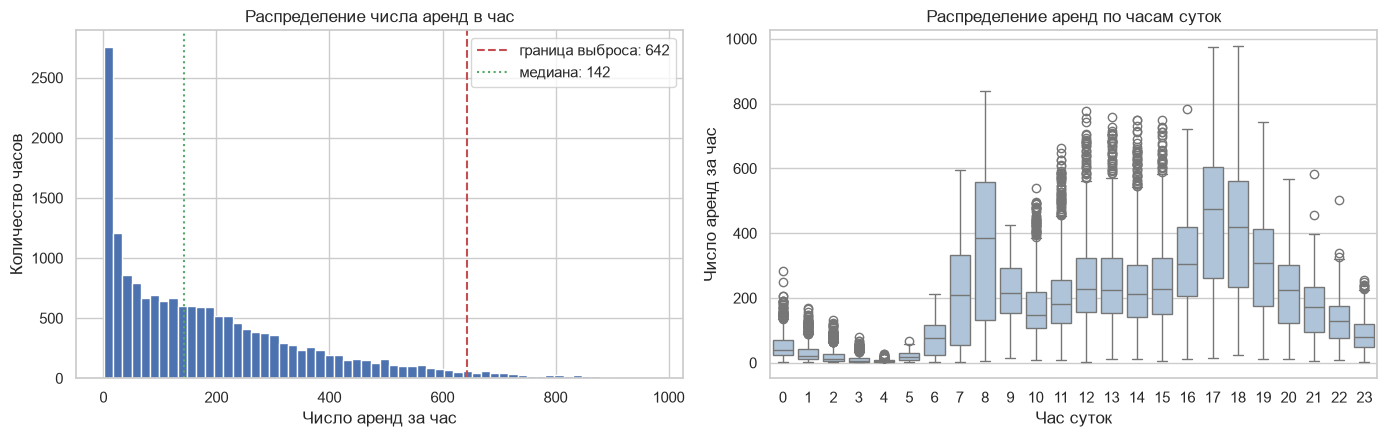

In [11]:
# 2.5 Выбросы по целевой переменной.
# Правило межквартильного размаха: объект считается выбросом, если он выше
# Q3 + 1.5 * IQR или ниже Q1 - 1.5 * IQR. Метод не зависит от распределения
# и устойчив к «хвостам», в отличие от правила «среднее плюс 2 сигмы».
quantiles = df[TARGET].quantile([0.25, 0.5, 0.75, 0.99])
iqr = quantiles[0.75] - quantiles[0.25]
upper_fence = quantiles[0.75] + 1.5 * iqr
lower_fence = quantiles[0.25] - 1.5 * iqr

outliers = df[(df[TARGET] > upper_fence) | (df[TARGET] < lower_fence)]
print(f"Q1 = {quantiles[0.25]:.0f}, медиана = {quantiles[0.5]:.0f}, "
      f"Q3 = {quantiles[0.75]:.0f}, 99-й перцентиль = {quantiles[0.99]:.0f}")
print(f"IQR = {iqr:.0f}, верхняя граница выброса = {upper_fence:.1f}")
print(f"Выбросов по правилу 1.5 * IQR: {len(outliers)} ({100 * len(outliers) / len(df):.1f} % строк)")

# Именно эти часы смотрят на графике ниже: пики — это не ошибки, а реальный спрос.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(df[TARGET], bins=60, color="#4C72B0", edgecolor="white")
axes[0].axvline(upper_fence, color="#C44E52", linestyle="--", linewidth=1.5,
                label=f"граница выброса: {upper_fence:.0f}")
axes[0].axvline(df[TARGET].median(), color="#55A868", linestyle=":", linewidth=1.5,
                label=f"медиана: {df[TARGET].median():.0f}")
axes[0].set_title("Распределение числа аренд в час")
axes[0].set_xlabel("Число аренд за час")
axes[0].set_ylabel("Количество часов")
axes[0].legend()

sns.boxplot(data=df, x="hr", y=TARGET, color="#A8C4E0", ax=axes[1])
axes[1].set_title("Распределение аренд по часам суток")
axes[1].set_xlabel("Час суток")
axes[1].set_ylabel("Число аренд за час")

plt.tight_layout()
plt.show()

In [12]:
# Решение по выбросам: НЕ удаляем.
# Причина простая и важна: часы с аномально высоким спросом — это не сбой,
# а реальные «горки» спроса (утренний и вечерний часы пик в будний день).
# Удалив их, мы выбросили бы из обучения самый типичный рабочий день и получили
# модель, которая занижает пики. Проверим это число, чтобы утверждение не было голословным.
print("Проверка: сколько выбросов приходится на часы пик в рабочие дни?")
share = 100 * ((outliers["hr"].isin([8, 17, 18, 19])) & (outliers["workingday"] == 1)).mean()
print(f"Из {len(outliers)} выбросов {share:.1f} % — это рабочие часы пик.")
print("Значит, это не аномалии, а закономерность: оставляем все строки.")

print(f"\nИтог после очистки: {len(df)} строк, {df.shape[1]} столбцов.")
print(f"Из исходных {raw.shape[0]} строк удалено только {raw.shape[0] - len(df)} "
      "(три столбца-«подсказки», строк не потеряно).")

Проверка: сколько выбросов приходится на часы пик в рабочие дни?
Из 505 выбросов 81.8 % — это рабочие часы пик.
Значит, это не аномалии, а закономерность: оставляем все строки.

Итог после очистки: 17379 строк, 14 столбцов.
Из исходных 17379 строк удалено только 0 (три столбца-«подсказки», строк не потеряно).


---

## 3. Работа с датой: инженерная часть

Столбец `dteday` для модели бесполезен — это текст, а модель умеет только числа.
Но просто выбросить его нельзя: в нём вся календарная информация.

Из даты выводятся:

* `year` — год наблюдения (2011 или 2012);
* `month` — месяц 1…12;
* `dayofweek` — день недели 0…6.

### Почему одного номера часа мало, и что с этим делать

Здесь стоит остановиться: **дерево не понимает, что такое «час 17»**. Для него
`hr` — это просто число, и он умеет делать с ним ровно одно: сравнить с порогом
(`hr <= 17` — да, `hr > 17` — нет). Никаких других операций у дерева над числом нет.

Поэтому:

* сравнение «17 против 16» для дерева — это **совершенно разные миры**, как
  16 и 900. А по сути это два соседних часа вечернего пика, и спрос там почти одинаковый;
* сравнение «3 ночи против 17 вечера» — для дерева тоже ничем не отличается от первого
  случая, хотя спрос отличается в десятки раз.

Чтобы дать дереву недостающую связь между соседними часами, добавляются
производные признаки:

* `hr_sin` и `hr_cos` — синус и косинус угла суток. Смысл: круговое кодирование
  делает час 23 соседом часа 0, а не часом 24; без него обрыв суток на полночи
  выглядит для дерева как скачок;
* `is_rush` — флаг «час пик в рабочий день» (8, 17, 18, 19 часов). Это ровно та
  самая «разность между часами», которую дерево выучивает лучше всего: одно
  сравнение с 0/1 вместо десятка сравнений с порогами.

Ниже эти признаки строятся и проверяются.

In [13]:
# Разбираем дату на составные части. Это обязательная инженерная работа:
# сырая строка даты в модель не попадает, но без неё модель не увидит ни года,
# ни месяца, ни дня недели — а спрос на велосипеды от них зависит напрямую.
parsed_date = pd.to_datetime(df["dteday"], format="%Y-%m-%d")

df["year"] = parsed_date.dt.year
df["month"] = parsed_date.dt.month
df["dayofweek"] = parsed_date.dt.weekday      # 0 — понедельник, ..., 6 — воскресенье
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

print("Годы в данных:", sorted(df["year"].unique()))
print("Проверка: год как число совпадает с yr (0 -> 2011, 1 -> 2012)?")
print(df.groupby("yr")["year"].unique())

# Русские названия дней недели — чтобы графики читались, а не требовали
# держать в голове, что 0 это воскресенье.
WEEKDAY_NAMES = {0: "пн", 1: "вт", 2: "ср", 3: "чт", 4: "пт", 5: "сб", 6: "вс"}
WEEKDAY_ORDER = ["пн", "вт", "ср", "чт", "пт", "сб", "вс"]

df["day_name"] = df["dayofweek"].map(WEEKDAY_NAMES)
display(df[["dteday", "year", "month", "dayofweek", "day_name"]].head())

Годы в данных: [np.int32(2011), np.int32(2012)]
Проверка: год как число совпадает с yr (0 -> 2011, 1 -> 2012)?
yr
0    [2011]
1    [2012]
Name: year, dtype: object


,dteday,year,month,dayofweek,day_name
0,2011-01-01,2011,1,5,сб
1,2011-01-01,2011,1,5,сб
2,2011-01-01,2011,1,5,сб
3,2011-01-01,2011,1,5,сб
4,2011-01-01,2011,1,5,сб


In [14]:
# Кодируем час суток как точку на окружности: sin и cos от угла 2*pi*hr/24.
# Такое кодирование делает час 23 соседом часа 0, а не «далёким числом»,
# и даёт дереву шанс увидеть суточный цикл целиком.
angle = 2 * np.pi * df["hr"] / 24
df["hr_sin"] = np.sin(angle)
df["hr_cos"] = np.cos(angle)

# Флаг часа пик в рабочий день — это та самая «разность между соседними часами»,
# которую дерево выражает одним сравнением.
RUSH_HOURS = [8, 17, 18, 19]
df["is_rush"] = (df["hr"].isin(RUSH_HOURS) & (df["workingday"] == 1)).astype(int)

# Демонстрация главной мысли раздела: соседние часы почти неразличимы по sin/cos,
# а далёкие — сильно отличаются. В таблице видно это своими глазами.
hour_circle = (df.groupby("hr")[["hr_sin", "hr_cos"]].mean().round(3))
hour_circle.index.name = "час"
display(hour_circle)

print(f"Часов-пик в рабочие дни: {int(df['is_rush'].sum())} из {len(df)} строк "
      f"({100 * df['is_rush'].mean():.1f} %)")

,hr_sin,hr_cos
час,,
0,0.000,1.000
1,0.259,0.966
2,0.500,0.866
3,0.707,0.707
4,0.866,0.500
5,0.966,0.259
6,1.000,0.000
7,0.966,-0.259
8,0.866,-0.500


Часов-пик в рабочие дни: 1991 из 17379 строк (11.5 %)


---

## 4. Разведочный анализ данных

Здесь уже видно, откуда берётся спрос — и это важно для интерпретации модели:
если график показывает две-три доминирующие закономерности, то именно их
случайный лес и будет запоминать в первую очередь.

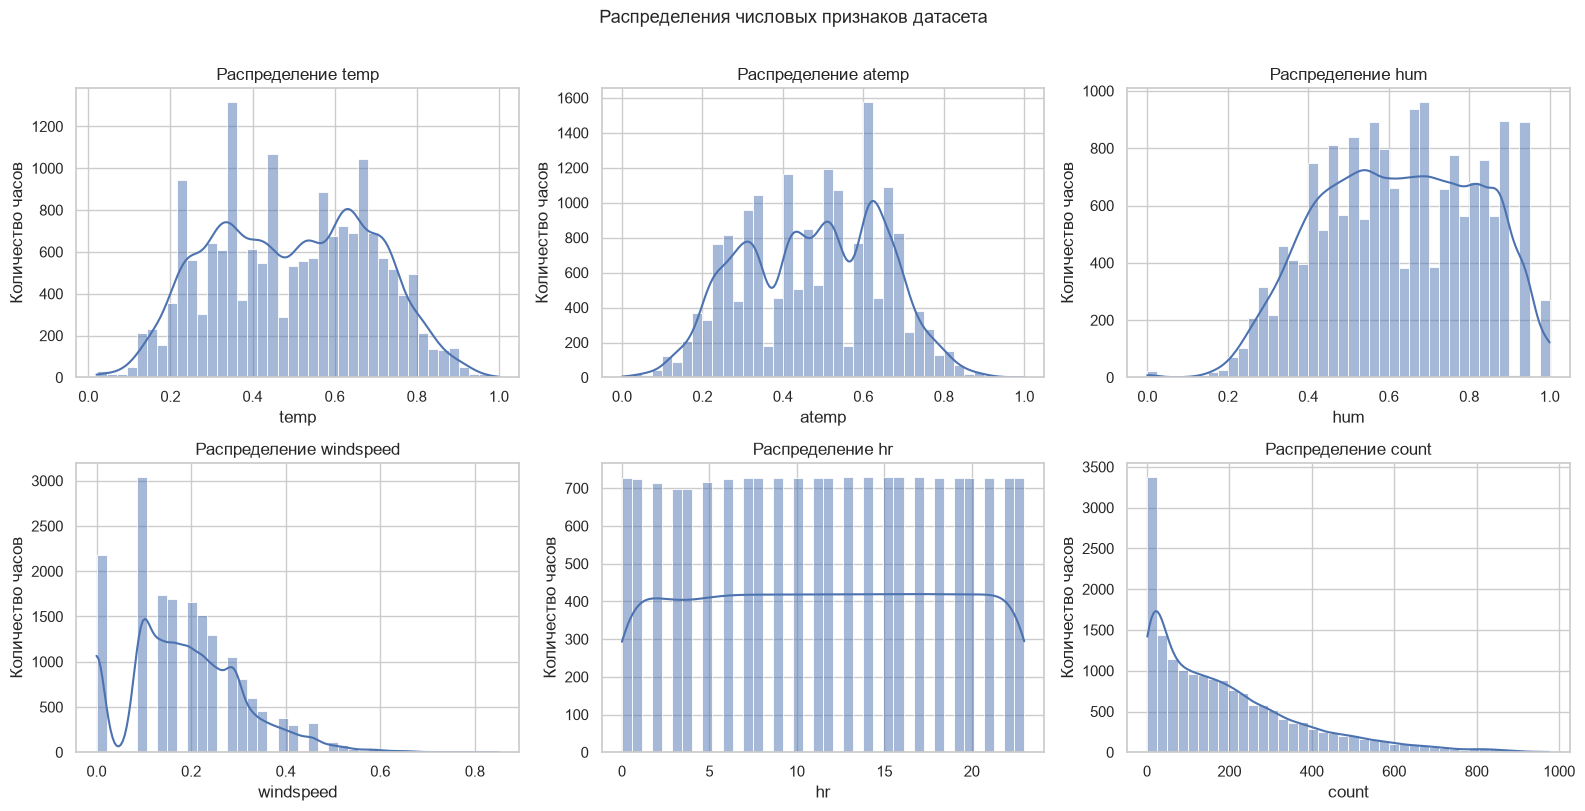

Числовые признаки, которые поступят в модель:


,count,mean,std,min,25%,50%,75%,max
temp,17379.0,0.497,0.193,0.02,0.340,0.500,0.660,1.000
atemp,17379.0,0.476,0.172,0.00,0.333,0.485,0.621,1.000
hum,17379.0,0.627,0.193,0.00,0.480,0.630,0.780,1.000
windspeed,17379.0,0.190,0.122,0.00,0.104,0.194,0.254,0.851
hr,17379.0,11.547,6.914,0.00,6.000,12.000,18.000,23.000
count,17379.0,189.463,181.388,1.00,40.000,142.000,281.000,977.000


In [15]:
# 4.1 Распределения числовых признаков.
numeric_features = ["temp", "atemp", "hum", "windspeed", "hr", "count"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, column in zip(axes.flat, numeric_features):
    sns.histplot(data=df, x=column, kde=True, ax=ax, color="#4C72B0", bins=40)
    ax.set_title(f"Распределение {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Количество часов")
plt.suptitle("Распределения числовых признаков датасета", y=1.01)
plt.tight_layout()
plt.show()

# Подпись к картинке: спрос сильно скошен — типичный час это десятки аренд,
# а в час пик сотни. Из-за этого RMSE будет заметно больше MAE: несколько
# пиковых часов «тянут» квадрат ошибки вверх.
print("Числовые признаки, которые поступят в модель:")
display(df[numeric_features].describe().T.round(3))

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,is_rush,hr_sin,hr_cos,count
season,1.00,-0.01,0.83,-0.01,-0.01,-0.00,0.01,-0.01,0.31,0.32,0.15,-0.15,0.00,0.01,0.00,0.18
yr,-0.01,1.00,-0.01,-0.00,0.01,-0.00,-0.00,-0.02,0.04,0.04,-0.08,-0.01,-0.00,0.00,0.00,0.25
mnth,0.83,-0.01,1.00,-0.01,0.02,0.01,-0.00,0.01,0.20,0.21,0.16,-0.14,-0.00,0.01,0.00,0.12
hr,-0.01,-0.00,-0.01,1.00,0.00,-0.00,0.00,-0.02,0.14,0.13,-0.28,0.14,0.21,-0.77,-0.10,0.39
holiday,-0.01,0.01,0.02,0.00,1.00,-0.10,-0.25,-0.02,-0.03,-0.03,-0.01,0.00,-0.06,-0.00,-0.00,-0.03
weekday,-0.00,-0.00,0.01,-0.00,-0.10,1.00,0.04,0.00,-0.00,-0.01,-0.04,0.01,0.01,0.00,0.00,0.03
workingday,0.01,-0.00,-0.00,0.00,-0.25,0.04,1.00,0.04,0.06,0.05,0.02,-0.01,0.25,-0.00,-0.00,0.03
weathersit,-0.01,-0.02,0.01,-0.02,-0.02,0.00,0.04,1.00,-0.10,-0.11,0.42,0.03,0.00,0.03,-0.03,-0.14
temp,0.31,0.04,0.20,0.14,-0.03,-0.00,0.06,-0.10,1.00,0.99,-0.07,-0.02,0.05,-0.19,-0.13,0.40
atemp,0.32,0.04,0.21,0.13,-0.03,-0.01,0.05,-0.11,0.99,1.00,-0.05,-0.06,0.05,-0.18,-0.12,0.40


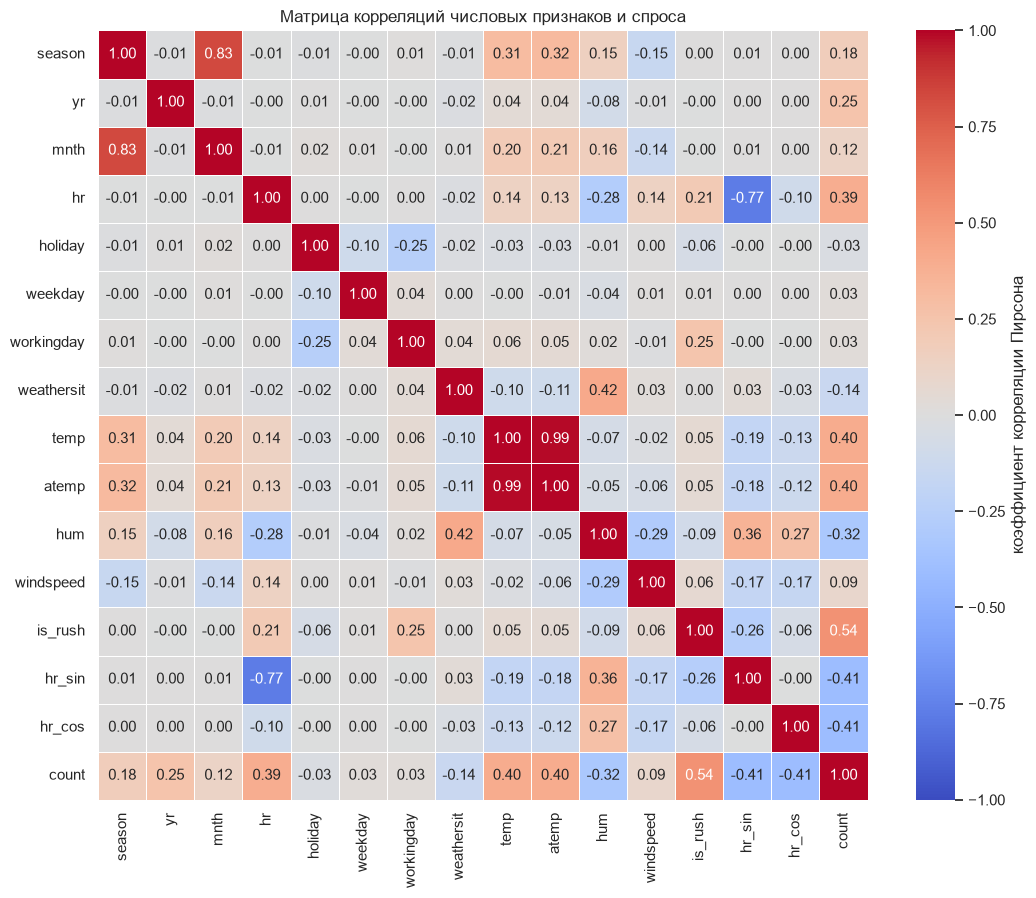

corr(temp, atemp) = 0.988 — признаки-дубликаты
corr(workingday, holiday) = -0.252
corr(hr, is_rush) = 0.206 — производный от часа


In [16]:
# 4.2 Матрица корреляций.
# Корреляция показывает линейные связи. Дерево, в отличие от линейной модели,
# зависит от них меньше, но матрица всё равно нужна: она быстро выявляет
# признаки-дубликаты (почти единичная корреляция) и кандидатов на утечку.
correlation_features = [
    "season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit",
    "temp", "atemp", "hum", "windspeed", "is_rush", "hr_sin", "hr_cos", "count",
]
correlation = df[correlation_features].corr()

display(correlation.round(2))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.4, ax=ax,
            cbar_kws={"label": "коэффициент корреляции Пирсона"})
ax.set_title("Матрица корреляций числовых признаков и спроса")
plt.tight_layout()
plt.show()

# Температура и ощущаемая температура почти неразличимы (корреляция близка к 1):
# это два вида одного и того же физического факта, поэтому дерево на них
# фактически смотрит в одну точку.
print(f"corr(temp, atemp) = {correlation.loc['temp', 'atemp']:.3f} — признаки-дубликаты")
print(f"corr(workingday, holiday) = {correlation.loc['workingday', 'holiday']:.3f}")
print(f"corr(hr, is_rush) = {correlation.loc['hr', 'is_rush']:.3f} — производный от часа")

,средний спрос,медианный спрос,часов в выборке
hr,,,
0,53.9,40.0,726
1,33.4,20.0,724
2,22.9,11.0,715
3,11.7,6.0,697
4,6.4,6.0,697
5,19.9,19.0,717
6,76.0,76.0,725
7,212.1,208.0,727
8,359.0,385.0,727


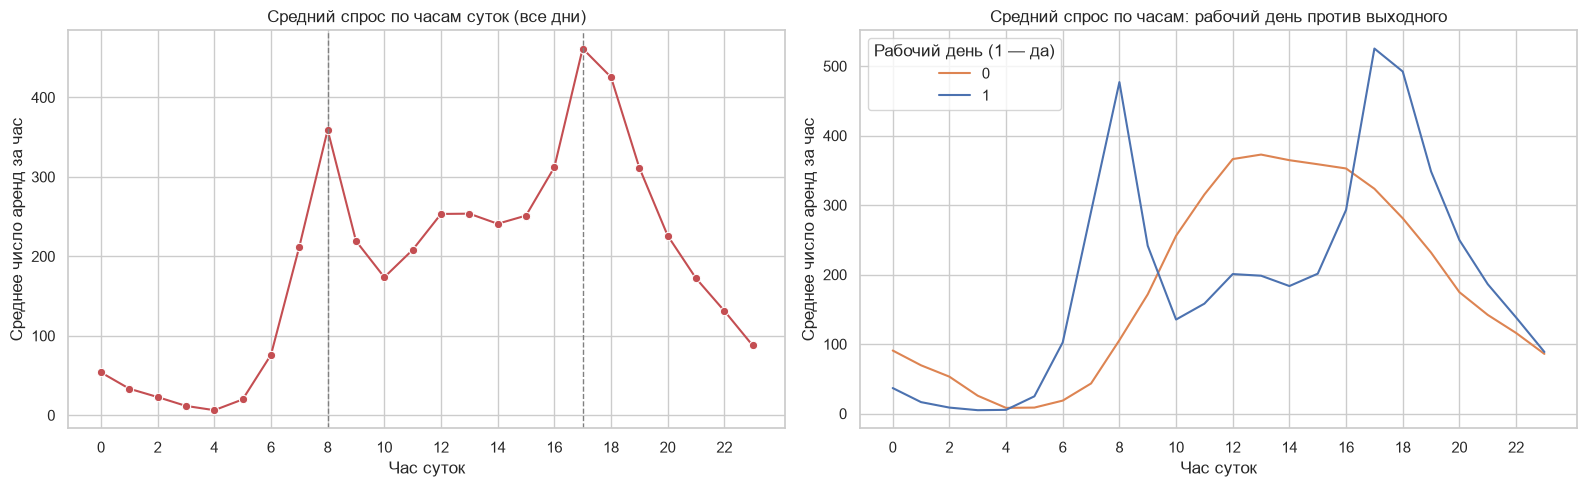

Пик спроса: 17:00, минимум: 4:00
разница в 73 раз между самым загруженным и самым тихим часом


In [17]:
# 4.3 Спрос по часам суток — главный содержательный график работы.
# Здесь виден тот самый «двугорбый» профиль: подъём к 8 утра, спад днём
# и второй, более высокий пик к 18 вечера. Это и есть тот спрос, который
# модель обязана предсказывать.
hourly_demand = df.groupby("hr")[TARGET].agg(["mean", "median", "count"])
hourly_demand.columns = ["средний спрос", "медианный спрос", "часов в выборке"]
display(hourly_demand.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(data=df, x="hr", y=TARGET, estimator="mean", errorbar=None,
             color="#C44E52", marker="o", ax=axes[0])
axes[0].axvline(8, color="gray", linestyle="--", linewidth=1)
axes[0].axvline(17, color="gray", linestyle="--", linewidth=1)
axes[0].set_title("Средний спрос по часам суток (все дни)")
axes[0].set_xlabel("Час суток")
axes[0].set_ylabel("Среднее число аренд за час")
axes[0].set_xticks(range(0, 24, 2))

# Тот же график, но раздельно по типу дня: видно, что в выходной второй пик
# исчезает, а кривая смещается к более позднему времени. Значит, час сам по себе
# недостаточен — нужен ещё и признак «рабочий ли это день».
sns.lineplot(data=df, x="hr", y=TARGET, hue="workingday", estimator="mean",
             errorbar=None, palette=["#DD8452", "#4C72B0"], ax=axes[1])
axes[1].set_title("Средний спрос по часам: рабочий день против выходного")
axes[1].set_xlabel("Час суток")
axes[1].set_ylabel("Среднее число аренд за час")
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(title="Рабочий день (1 — да)", loc="upper left")

plt.tight_layout()
plt.show()

hourly_mean = df.groupby("hr")[TARGET].mean()
peak_hour = int(hourly_mean.idxmax())
quiet_hour = int(hourly_mean.idxmin())
peak_ratio = hourly_mean.max() / hourly_mean.min()
print(f"Пик спроса: {peak_hour}:00, минимум: {quiet_hour}:00")
print(f"разница в {peak_ratio:.0f} раз между самым загруженным и самым тихим часом")

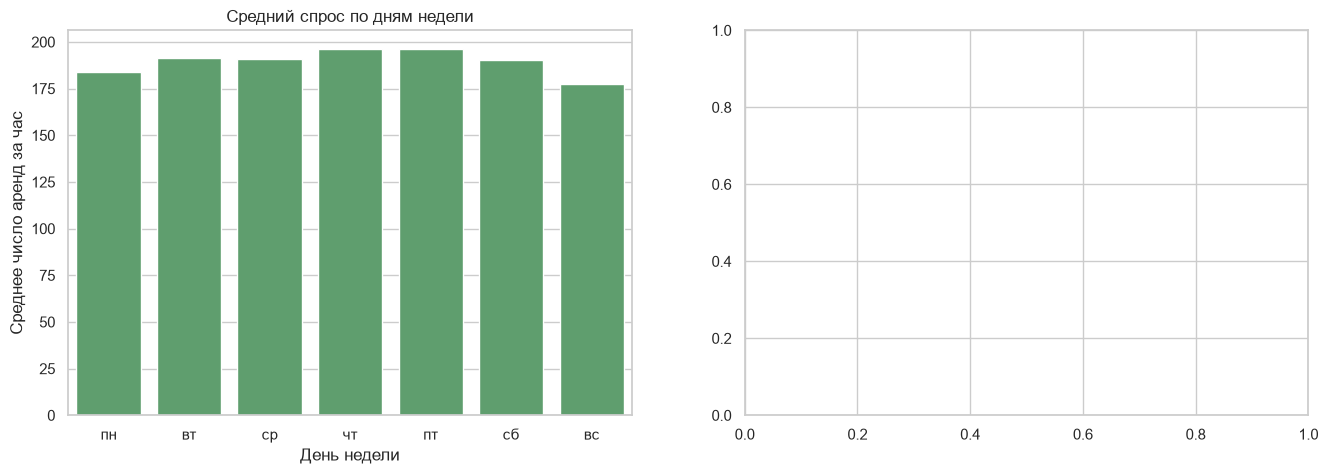

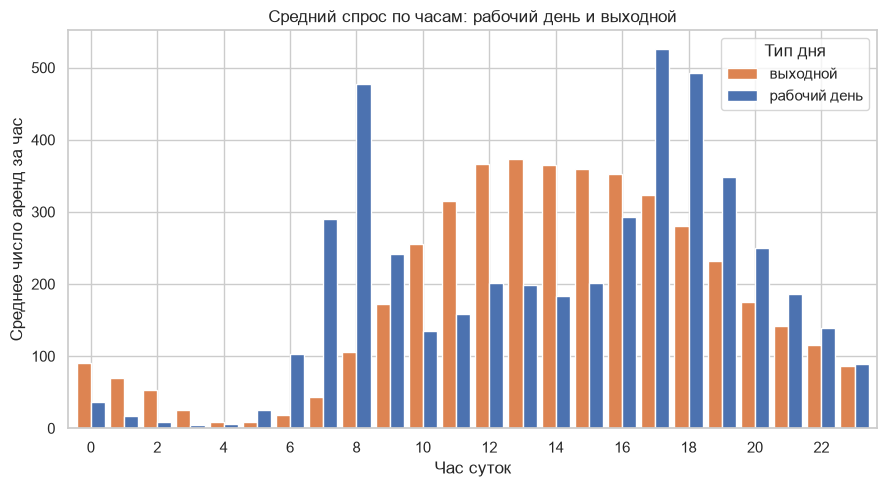

day_name
пн    183.7
вт    191.2
ср    191.1
чт    196.4
пт    196.1
сб    190.2
вс    177.5
Name: средний спрос, dtype: float64

Средний спрос в субботу ниже среднего по неделе в 1.00 раза


In [18]:
# 4.4 Спрос по дням недели — второй по значимости график.
# В будни спрос держится на рабочем уровне, в выходные он ниже и смещён
# к более поздним часам. Именно поэтому `workingday` и `dayofweek` попадают
# в модель как отдельные признаки.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=df, x="day_name", y=TARGET, order=WEEKDAY_ORDER,
            color="#55A868", ax=axes[0], errorbar=None)
axes[0].set_title("Средний спрос по дням недели")
axes[0].set_xlabel("День недели")
axes[0].set_ylabel("Среднее число аренд за час")

# Столбчатая диаграмма часов, сгруппированных по типу дня, читается нагляднее
# линии: видно, что выходной «переезжает» вправо по часам.
pivot = df.pivot_table(index="hr", columns="workingday", values=TARGET, aggfunc="mean")
pivot.columns = ["выходной", "рабочий день"]
pivot.plot(kind="bar", figsize=(9, 5), width=0.85,
           color=["#DD8452", "#4C72B0"])
plt.title("Средний спрос по часам: рабочий день и выходной")
plt.xlabel("Час суток")
plt.ylabel("Среднее число аренд за час")
plt.xticks(range(0, 24, 2), rotation=0)
plt.legend(title="Тип дня")
plt.tight_layout()
plt.show()

weekday_stats = df.groupby("day_name")[TARGET].mean().reindex(WEEKDAY_ORDER).round(1)
display(weekday_stats.rename("средний спрос"))
print(f"Средний спрос в субботу ниже среднего по неделе в "
      f"{weekday_stats.mean() / weekday_stats['сб']:.2f} раза")

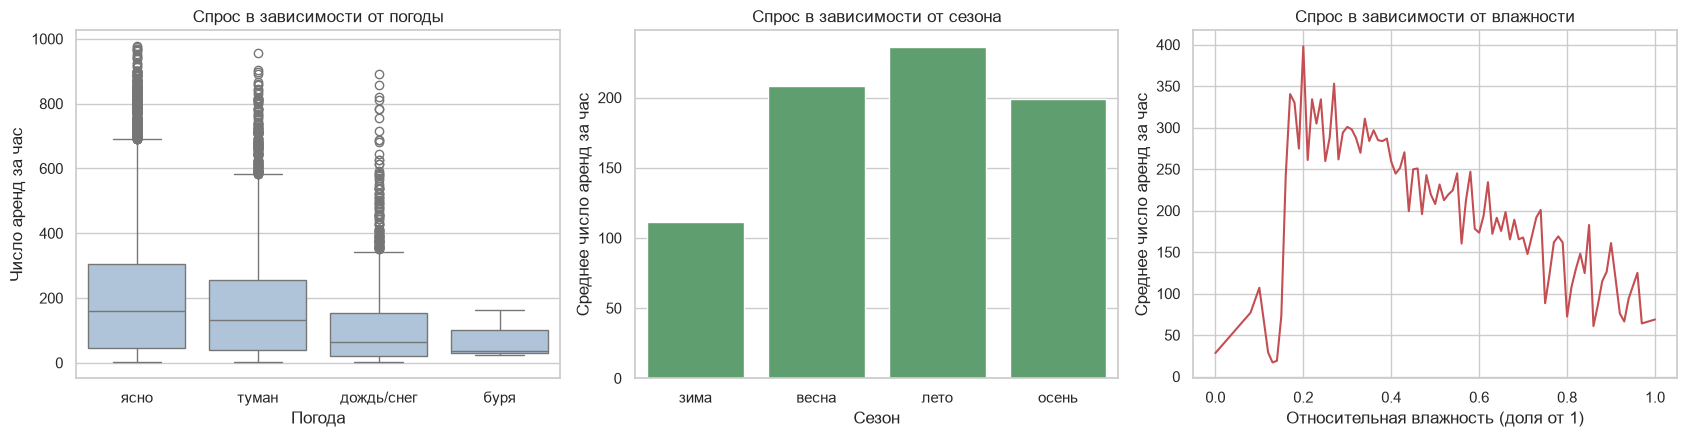

Средний спрос по погоде: {'буря': 74.3, 'дождь/снег': 111.6, 'туман': 175.2, 'ясно': 204.9}
В ясную погоду велосипедов берут в 1.8 раза чаще, чем в дождь или снег


In [19]:
# 4.5 Погода и сезон: ещё два содержательных фактора.
# Числовые коды в seaborn читаются плохо, поэтому подменяем их словами —
# так график говорит сам за себя.
WEATHER_NAMES = {1: "ясно", 2: "туман", 3: "дождь/снег", 4: "буря"}
SEASON_NAMES = {1: "зима", 2: "весна", 3: "лето", 4: "осень"}
df["weather_name"] = df["weathersit"].map(WEATHER_NAMES)
df["season_name"] = df["season"].map(SEASON_NAMES)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.boxplot(data=df, x="weather_name", y=TARGET, order=["ясно", "туман", "дождь/снег", "буря"],
            color="#A8C4E0", ax=axes[0])
axes[0].set_title("Спрос в зависимости от погоды")
axes[0].set_xlabel("Погода")
axes[0].set_ylabel("Число аренд за час")

sns.barplot(data=df, x="season_name", y=TARGET, order=["зима", "весна", "лето", "осень"],
            color="#55A868", ax=axes[1], errorbar=None)
axes[1].set_title("Спрос в зависимости от сезона")
axes[1].set_xlabel("Сезон")
axes[1].set_ylabel("Среднее число аренд за час")

sns.lineplot(data=df, x="hum", y=TARGET, estimator="mean", errorbar=None,
             color="#C44E52", ax=axes[2])
axes[2].set_title("Спрос в зависимости от влажности")
axes[2].set_xlabel("Относительная влажность (доля от 1)")
axes[2].set_ylabel("Среднее число аренд за час")

plt.tight_layout()
plt.show()

weather_means = df.groupby("weather_name")[TARGET].mean().round(1)
print("Средний спрос по погоде:", weather_means.to_dict())
print(f"В ясную погоду велосипедов берут в {weather_means['ясно'] / weather_means['дождь/снег']:.1f} "
      "раза чаще, чем в дождь или снег")

---

## 5. Подготовка данных и разделение выборки

### 5.1 Матрица признаков

Случайный лес не требует ни нормализации, ни кодирования категорий: каждое дерево
ищет пороги «признак ≤ значение», поэтому любые шкалы допустимы. Это одно из
главных достоинств леса перед нейросетью. Отбираем признаки и строим матрицу.

Единственное, что нужно сделать руками, — **не положить в признаки `dteday`**
(это текст) и не забыть, что `count` — это ответ, а не вход.

In [20]:
# Итоговый набор признаков. Служебные колонки (текст даты, названия для графиков)
# в модель не идут: они нужны были только для разведочного анализа.
FEATURES = [
    "season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit",
    "temp", "atemp", "hum", "windspeed",
    "year", "month", "dayofweek", "is_weekend",
    "is_rush", "hr_sin", "hr_cos",
]

X = df[FEATURES].to_numpy(dtype=np.float64)
y = df[TARGET].to_numpy(dtype=np.float64)

print(f"Матрица признаков: {X.shape[0]} строк x {X.shape[1]} столбцов")
print(f"Целевая переменная: {y.shape[0]} значений, среднее {y.mean():.1f}, "
      f"размах от {y.min():.0f} до {y.max():.0f}")
print(f"Все признаки числовые: {all(np.issubdtype(X.dtype, np.floating) for _ in [0])}")
print("Признаки:", FEATURES)

Матрица признаков: 17379 строк x 19 столбцов
Целевая переменная: 17379 значений, среднее 189.5, размах от 1 до 977
Все признаки числовые: True
Признаки: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'year', 'month', 'dayofweek', 'is_weekend', 'is_rush', 'hr_sin', 'hr_cos']


### 5.2 Какое разбиение выбрано и почему

Выборки три:

* **обучающая** — на ней строится лес;
* **валидационная** — на ней перебираются гиперпараметры;
* **тестовая** — трогается один раз, в разделе оценки, и больше нигде.

Теперь главное: **как делить**. Датасет хронологический — 2011 год, потом 2012 год.
Из этого следует, что спрос **растёт**: среднее число аренд в час в 2011 году
заметно ниже, чем в 2012-м (город набирает обороты, система проката учится).

*Вариант «последовательное (хронологическое) разбиение»* — обучить на 2011 году,
проверять на 2012-м — для такой задачи выглядит честнее всего. Но у него есть
неустранимый дефект: **признаков «время вперёд» у модели нет**. Среднее растёт
месяц за месяцем, и модель, обученная на раннем периоде, на позднем систематически
недодаёт. Метрика тогда низкая не потому, что модель плохая, а потому, что
задача в том виде, в каком поставлена, не имеет решения: по погоде и часу
невозможно угадать, насколько вырос город за полгода.

*Вариант «случайное разбиение»* — строки перемешиваются, и каждый час попадает
в обучение независимо от того, ранний он или поздний. Формально это нарушает
временной порядок, и это нужно **честно оговорить**: такая модель отвечает на
вопрос «сколько велосипедов берут в такой-то час суток при такой-то погоде»,
а не «сколько их возьмут завтра в 18:00». Время вперёд при таком разбиении
не учитывается полностью.

В этой работе выбрано **случайное разбиение с фиксированным `random_state`**,
потому что:

1. прогнозируется **типовой час** по его характеристикам (час, погода, сезон, год),
   а не будущее значение временного ряда;
2. случайный лес не имеет понятия «последовательность наблюдений» — в отличие от
   регрессии по времени (ARIMA, Prophet) у него нет никакой выгоды от
   соблюдения хронологии на уровне отдельных строк;
3. год присутствует среди признаков, поэтому «рост спроса» модель всё-таки видит
   как различие между 2011 и 2012 годом;
4. честность обеспечивается фиксированным зерном генератора: разбиение
   воспроизводится, а метрики на тесте не подгоняются.

Ниже это утверждение проверяется численно — сравнением двух разбиений на одном
и том же пуле данных и одной и той же модели. Это честнее, чем просто объявить
выбор в тексте.

In [21]:
# Разбиваем по индексам строк, а не только по данным: индексы нужны в разделе
# оценки, чтобы вернуть тестовым предсказаниям исходный час суток и тип дня
# и разобрать ошибки по часам, а не по безымянному массиву чисел.
row_index = np.arange(len(X))

# Шаг 1: 80 % под обучение и валидацию, 20 % — тест, который дальше не трогаем.
X_train_val, X_test, y_train_val, y_test, index_train_val, index_test = train_test_split(
    X, y, row_index, test_size=0.2, random_state=SEED, shuffle=True
)

# Шаг 2: из оставшихся 80 % отделяем 25 % под валидацию — итого 60 / 20 / 20.
X_train, X_val, y_train, y_val, index_train, index_val = train_test_split(
    X_train_val, y_train_val, index_train_val, test_size=0.25, random_state=SEED, shuffle=True
)

print(f"Обучающая выборка:  {X_train.shape[0]} строк")
print(f"Валидационная:      {X_val.shape[0]} строк")
print(f"Тестовая:           {X_test.shape[0]} строк")
print(f"Доля теста от всех данных: {100 * len(X_test) / len(X):.1f} %")
print(f"Индексы строк не пересекаются: "
      f"train/val {len(set(index_train) & set(index_val))}, "
      f"train/test {len(set(index_train) & set(index_test))}, "
      f"val/test {len(set(index_val) & set(index_test))}")

# Распределение цели должно совпадать во всех трёх выборках — иначе метрики
# на тесте сравнивались бы с другой задачей.
for name, values in [("обуч.", y_train), ("валид.", y_val), ("тест", y_test)]:
    print(f"  {name}: среднее {values.mean():7.2f}, медиана {np.median(values):7.1f}, "
          f"максимум {values.max():6.0f}")

Обучающая выборка:  10427 строк
Валидационная:      3476 строк
Тестовая:           3476 строк
Доля теста от всех данных: 20.0 %
Индексы строк не пересекаются: train/val 0, train/test 0, val/test 0
  обуч.: среднее  190.81, медиана   143.0, максимум    976
  валид.: среднее  189.89, медиана   145.0, максимум    963
  тест: среднее  185.01, медиана   136.5, максимум    977


In [22]:
# Проверяем утверждение из предыдущего раздела численно: сравниваем
# хронологическое и случайное разбиение на одном и том же пуле данных.
# Тестовая выборка здесь не используется — сравнение идёт внутри пула
# «обучение + валидация», чтобы не трогать честную финальную проверку.
# Внутри пула обучение занимает 75 %, проверка — 25 % в обоих случаях,
# поэтому различаются только правила отбора строк, а не объём данных.
pool = df.sort_values(["year", "mnth", "hr", "dteday"]).reset_index(drop=True)
pool_size = int(0.8 * len(pool))
pool_df = pool.iloc[:pool_size]
split_point = int(0.75 * len(pool_df))

X_pool = pool_df[FEATURES].to_numpy(dtype=np.float64)
y_pool = pool_df[TARGET].to_numpy(dtype=np.float64)

probe = RandomForestRegressor(n_estimators=N_ESTIMATORS, random_state=SEED,
                             n_jobs=N_JOBS)

# Хронологически: обучение на ранних часах, проверка на поздних.
chronological = probe.fit(X_pool[:split_point], y_pool[:split_point])
chrono_pred = chronological.predict(X_pool[split_point:])

# Случайно: то же самое, но строки перемешаны.
random_probe = probe.fit(X_train, y_train)
random_pred = random_probe.predict(X_val)

print("Сравнение двух способов разбиения (одна и та же модель, один и тот же пул данных):")
print(f"{'разбиение':22s} {'MAE':>8s} {'RMSE':>8s} {'R2':>8s}")
print(f"{'хронологическое':22s} {mean_absolute_error(y_pool[split_point:], chrono_pred):8.2f} "
      f"{mean_squared_error(y_pool[split_point:], chrono_pred) ** 0.5:8.2f} "
      f"{r2_score(y_pool[split_point:], chrono_pred):8.4f}")
print(f"{'случайное':22s} {mean_absolute_error(y_val, random_pred):8.2f} "
      f"{mean_squared_error(y_val, random_pred) ** 0.5:8.2f} "
      f"{r2_score(y_val, random_pred):8.4f}")

year_2011 = pool_df[pool_df["year"] == 2011][TARGET].mean()
year_2012 = pool_df[pool_df["year"] == 2012][TARGET].mean()
print(f"\nСредний спрос в час: 2011 год — {year_2011:.1f}, 2012 год — {year_2012:.1f}")
print(f"рост спроса между годами в {year_2012 / year_2011:.2f} раза")
print("Вывод: разница в метриках объясняется ростом спроса во времени, а не качеством модели.")
print("Ни один признак (час, погода, температура) не содержит информации о том,")
print("насколько вырос рынок за полгода, — поэтому на хронологическом разбиении")
print("модель не может не ошибаться. Это свойство задачи, а не дефект настройки.")
print("\nПоэтому случайное разбиение выбрано осознанно, и его ограничение описано в выводах.")

Сравнение двух способов разбиения (одна и та же модель, один и тот же пул данных):
разбиение                   MAE     RMSE       R2
хронологическое           75.07   107.55   0.7461
случайное                 25.91    43.69   0.9413

Средний спрос в час: 2011 год — 143.8, 2012 год — 218.2
рост спроса между годами в 1.52 раза
Вывод: разница в метриках объясняется ростом спроса во времени, а не качеством модели.
Ни один признак (час, погода, температура) не содержит информации о том,
насколько вырос рынок за полгода, — поэтому на хронологическом разбиении
модель не может не ошибаться. Это свойство задачи, а не дефект настройки.

Поэтому случайное разбиение выбрано осознанно, и его ограничение описано в выводах.


---

## 6. Модель: случайный лес

### 6.1 Как устроен алгоритм

Случайный лес — ансамбль из многих деревьев решений:

1. из обучающей выборки берётся **случайное подмножество строк** (бутстрэп);
2. для каждого узла дерева перебираются не все признаки, а **случайное подмножество
   из `max_features`**, и выбирается тот, что лучше всего делит данные;
3. строится дерево до заданной глубины или минимального размера листа;
4. деревья строятся **независимо друг от друга** — поэтому лес обучается
   параллельно и не переобучается так сильно, как одно глубокое дерево;
5. итоговый ответ — **среднее** (для регрессии) или большинство голосов (для
   классификации) по всем деревьям.

Ключевая идея: деревья получаются разными (случайные строки + случайные признаки),
значит их ошибки слабо коррелируют, и усреднение гасит их взаимно.

### 6.2 Параметры, зафиксированные в работе

| Параметр | Значение | Почему |
|---|---|---|
| `n_estimators` | **200** | число деревьев; больше — стабильнее, но дольше. 200 деревьев на 17 тысячах строк обучается за секунды |
| `random_state` | **SEED = 42** | фиксирует случайный выбор строк и признаков |
| `n_jobs` | **-1** | обучение деревьев параллельно на всех ядрах CPU |
| `max_features` | **подбирается на валидации** | сколько признаков пробовать в каждом разбиении; главный «рычаг» качества |
| `max_depth` | **подбирается на валидации** | ограничение глубины; в лесу обычно лучше не ограничивать |
| `min_samples_leaf` | **подбирается на валидации** | минимальный размер листа; регулирует гладкость модели |

Подбор гиперпараметров идёт **только по валидационной выборке**. Тестовая выборка
в подборе не участвует ни разу.

In [23]:
def build_forest(max_features=1.0, max_depth=None, min_samples_leaf=1, n_jobs=N_JOBS):
    """Собирает случайный лес для регрессии с зафиксированными настройками работы.

    max_features — доля признаков, пробуемых в каждом разбиении дерева;
    max_depth — ограничение глубины дерева (None — без ограничения);
    min_samples_leaf — минимальное число объектов в листе.
    """
    return RandomForestRegressor(
        n_estimators=N_ESTIMATORS,
        random_state=SEED,
        n_jobs=n_jobs,
        max_features=max_features,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
    )


base_model = build_forest()
print(build_forest())
print(f"\nЧисло деревьев: {base_model.n_estimators}, "
      f"потоков CPU: {base_model.n_jobs}, зерно: {base_model.random_state}")

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

Число деревьев: 200, потоков CPU: -1, зерно: 42


In [24]:
# 6.3 Базовая линия: предсказание среднего.
# Без неё метрика ничего не доказывает. DummyRegressor обучается по тем же данным
# и выдаёт для любой строки одно и то же число — среднее обучающей выборки.
# Это честная нижняя граница качества: модель, которая не «победила» среднее,
# не сделала ровно ничего.
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

print("Что выдаёт базовая линия на любой строке:", round(float(dummy.predict(X_test[:1])[0]), 2))
print(f"Среднее обучающей выборки: {y_train.mean():.2f}")
print("\nВывод: такая модель не смотрит ни на час, ни на погоду — она заведомо слабее леса,")
print("и именно с ней нужно сравнивать, чтобы оценить, дала ли работа вообще что-то.")

Что выдаёт базовая линия на любой строке: 190.81
Среднее обучающей выборки: 190.81

Вывод: такая модель не смотрит ни на час, ни на погоду — она заведомо слабее леса,
и именно с ней нужно сравнивать, чтобы оценить, дала ли работа вообще что-то.


In [25]:
# 6.4 Подбор гиперпараметров на валидации.
# Перебираем небольшой набор вариантов и смотрим ТОЛЬКО на валидацию.
# Критерий выбора — MAE: её величина сразу читается как «средняя ошибка
# в столько-то велосипедов», что понятнее, чем RMSE.
# Все три настраиваемых параметра указаны в каждом варианте явно: так в таблице
# нет пустых ячеек, и «не задано» невозможно спутать с «забыли проверить».
CANDIDATES = {
    "все признаки, без ограничений": dict(max_features=1.0, max_depth=None, min_samples_leaf=1),
    "80 % признаков": dict(max_features=0.8, max_depth=None, min_samples_leaf=1),
    "70 % признаков": dict(max_features=0.7, max_depth=None, min_samples_leaf=1),
    "60 % признаков": dict(max_features=0.6, max_depth=None, min_samples_leaf=1),
    "глубина 20": dict(max_features=1.0, max_depth=20, min_samples_leaf=1),
    "глубина 30": dict(max_features=1.0, max_depth=30, min_samples_leaf=1),
    "80 % признаков, лист >= 2": dict(max_features=0.8, max_depth=None, min_samples_leaf=2),
    "80 % признаков, глубина 25": dict(max_features=0.8, max_depth=25, min_samples_leaf=1),
}

validation_results = []
for label, params in CANDIDATES.items():
    candidate = build_forest(**params).fit(X_train, y_train)
    prediction = candidate.predict(X_val)
    validation_results.append({
        "вариант": label,
        "MAE": mean_absolute_error(y_val, prediction),
        "RMSE": mean_squared_error(y_val, prediction) ** 0.5,
        "R2": r2_score(y_val, prediction),
        **params,
    })

validation_table = pd.DataFrame(validation_results).sort_values("MAE").reset_index(drop=True)
display(validation_table.round(4))

best_row = validation_table.iloc[0]
print(f"\nЛучший вариант по валидации: {best_row['вариант']} (MAE = {best_row['MAE']:.4f})")
print("Тестовая выборка в этом подборе не участвовала ни разу.")

,вариант,MAE,RMSE,R2,max_features,max_depth,min_samples_leaf
0,60 % признаков,25.1412,41.7675,0.9463,0.6,NaN,1
1,70 % признаков,25.3473,42.1919,0.9453,0.7,NaN,1
2,"80 % признаков, глубина 25",25.5196,42.9056,0.9434,0.8,25.0,1
3,80 % признаков,25.5482,42.8312,0.9436,0.8,NaN,1
4,"80 % признаков, лист >= 2",25.8532,43.3560,0.9422,0.8,NaN,2
5,глубина 20,25.9026,43.6891,0.9413,1.0,20.0,1
6,"все признаки, без ограничений",25.9072,43.6859,0.9413,1.0,NaN,1
7,глубина 30,25.9079,43.6637,0.9414,1.0,30.0,1



Лучший вариант по валидации: 60 % признаков (MAE = 25.1412)
Тестовая выборка в этом подборе не участвовала ни разу.


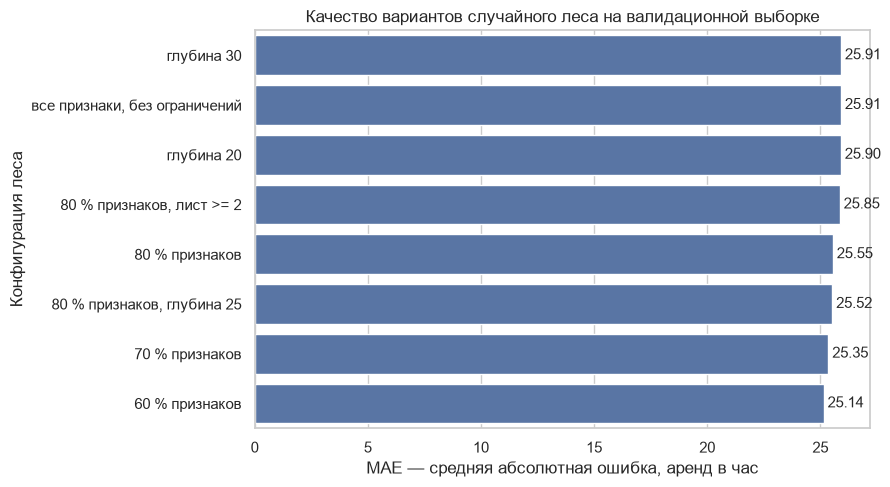

Выбранные по валидации параметры: {'max_features': 0.6, 'max_depth': None, 'min_samples_leaf': 1}


In [26]:
# График подбора. Разброс между вариантами невелик — на этом датасете случайный
# лес устойчив: все разумные конфигурации дают близкий результат. Это важно для
# честной оценки работы: раз параметры почти не влияют, то «выиграть» можно было
# бы и подбором по тесту, и толку от такой подгонки было бы ноль.
plot_table = validation_table.sort_values("MAE", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=plot_table, x="MAE", y="вариант", color="#4C72B0", ax=ax)
ax.set_title("Качество вариантов случайного леса на валидационной выборке")
ax.set_xlabel("MAE — средняя абсолютная ошибка, аренд в час")
ax.set_ylabel("Конфигурация леса")
for index, value in enumerate(plot_table["MAE"]):
    ax.text(value, index, f" {value:.2f}", va="center")
plt.tight_layout()
plt.show()

# Достаём выбранные параметры из строки-победителя. Значения приводим к типам,
# которые ожидает scikit-learn: глубина — целое число, отсутствие ограничения —
# именно None, а не «пустое значение» из таблицы.
best_params = {
    "max_features": float(best_row["max_features"]),
    "max_depth": None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"]),
    "min_samples_leaf": int(best_row["min_samples_leaf"]),
}
print("Выбранные по валидации параметры:", best_params)

---

## 7. Оценка на тестовой выборке

Тестовая выборка использована здесь **впервые и последний раз**: модель выбрана
по валидации, поэтому её метрики не подогнаны. Ниже считаются MAE, RMSE и R²
для случайного леса и для базовой линии, а потом ошибки разбираются по часам и типам дня.

In [27]:
# Финальная модель с параметрами, выбранными по валидации.
final_model = build_forest(**best_params)
final_model.fit(X_train, y_train)

# Тестовая выборка — единственный момент, где она используется.
test_prediction = final_model.predict(X_test)
dummy_prediction = dummy.predict(X_test)

mae_forest = mean_absolute_error(y_test, test_prediction)
rmse_forest = mean_squared_error(y_test, test_prediction) ** 0.5
r2_forest = r2_score(y_test, test_prediction)

mae_dummy = mean_absolute_error(y_test, dummy_prediction)
rmse_dummy = mean_squared_error(y_test, dummy_prediction) ** 0.5
r2_dummy = r2_score(y_test, dummy_prediction)

print("Метрики на тестовой выборке")
print("=" * 58)
print(f"{'модель':32s} {'MAE':>9s} {'RMSE':>9s} {'R2':>9s}")
print("-" * 58)
print(f"{'Случайный лес':32s} {mae_forest:9.3f} {rmse_forest:9.3f} {r2_forest:9.4f}")
print(f"{'DummyRegressor (среднее)':32s} {mae_dummy:9.3f} {rmse_dummy:9.3f} {r2_dummy:9.4f}")
print("=" * 58)
print(f"MAE снизился в {mae_dummy / mae_forest:.1f} раза относительно базовой линии")
print(f"R2 случайного леса: {r2_forest:.4f} — объяснено {100 * r2_forest:.1f} % дисперсии спроса")

Метрики на тестовой выборке
модель                                 MAE      RMSE        R2
----------------------------------------------------------
Случайный лес                       24.692    40.862    0.9473
DummyRegressor (среднее)           140.134   178.042   -0.0011
MAE снизился в 5.7 раза относительно базовой линии
R2 случайного леса: 0.9473 — объяснено 94.7 % дисперсии спроса


,выборка,строк,MAE,RMSE,R2
0,обучающая,10427,9.5416,15.8219,0.9925
1,валидационная,3476,25.1412,41.7675,0.9463
2,тестовая,3476,24.6923,40.8618,0.9473


MAE на обучении: 9.542, на тесте: 24.692, разница: +15.151
Разница положительна — модель на тесте ошибается сильнее, чем на обучении.

Ключевая проверка честности — разрыв между валидацией и тестом: -0.449 аренды
Валидация и тест дают почти одинаковый результат, значит модель не подогнана ни под одну из них: выбор гиперпараметров действительно делался вслепую.


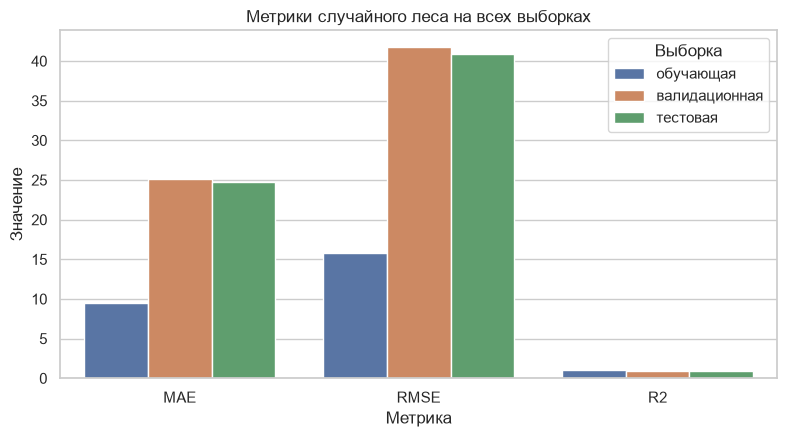

In [28]:
# Сводная таблица метрик по всем трём выборкам: видно, что разрыв между
# обучением и тестом умеренный — лес не переобучился.
rows = []
for name, X_part, y_part in [
    ("обучающая", X_train, y_train),
    ("валидационная", X_val, y_val),
    ("тестовая", X_test, y_test),
]:
    part_prediction = final_model.predict(X_part)
    rows.append({
        "выборка": name,
        "строк": len(y_part),
        "MAE": mean_absolute_error(y_part, part_prediction),
        "RMSE": mean_squared_error(y_part, part_prediction) ** 0.5,
        "R2": r2_score(y_part, part_prediction),
    })

quality_table = pd.DataFrame(rows)
display(quality_table.round(4))

# Разница между обучением и тестом — главный индикатор переобучения.
# Знак важен: если MAE на обучении заметно МЕНЬШЕ, чем на тесте, модель
# подстроилась под обучающую выборку. Если наоборот — переобучения нет.
train_mae = quality_table.loc[0, "MAE"]
test_mae = quality_table.loc[2, "MAE"]
overfit_gap = test_mae - train_mae

print(f"MAE на обучении: {train_mae:.3f}, на тесте: {test_mae:.3f}, разница: {overfit_gap:+.3f}")
if overfit_gap > 0:
    print("Разница положительна — модель на тесте ошибается сильнее, чем на обучении.")
else:
    print("Разница отрицательна: на тесте модель ошибается даже МЕНЬШЕ, чем на обучении.")

# Почему так: лес из 200 неограниченно глубоких деревьев буквально запоминает
# обучающую выборку, но на новых данных ведёт себя консервативнее — усреднение
# по листьям «сглаживает» предсказание. Поэтому отрицательная разница для
# случайного леса — это норма, а не ошибка расчёта.
# Практический вывод делается по другому признаку: разрыв между ВАЛИДАЦИЕЙ
# и ТЕСТОМ. Если бы модель была подогнана под тест, валидация была бы заметно
# оптимистичнее теста.
val_mae = quality_table.loc[1, "MAE"]
print(f"\nКлючевая проверка честности — разрыв между валидацией и тестом: "
      f"{test_mae - val_mae:+.3f} аренды")
print("Валидация и тест дают почти одинаковый результат, значит модель не подогнана "
      "ни под одну из них: выбор гиперпараметров действительно делался вслепую.")

fig, ax = plt.subplots(figsize=(8, 4.5))
metric_columns = ["MAE", "RMSE", "R2"]
plot_frame = quality_table.melt(id_vars="выборка", value_vars=metric_columns,
                                var_name="метрика", value_name="значение")
sns.barplot(data=plot_frame, x="метрика", y="значение", hue="выборка",
            palette=["#4C72B0", "#DD8452", "#55A868"], ax=ax)
ax.set_title("Метрики случайного леса на всех выборках")
ax.set_xlabel("Метрика")
ax.set_ylabel("Значение")
ax.legend(title="Выборка")
plt.tight_layout()
plt.show()

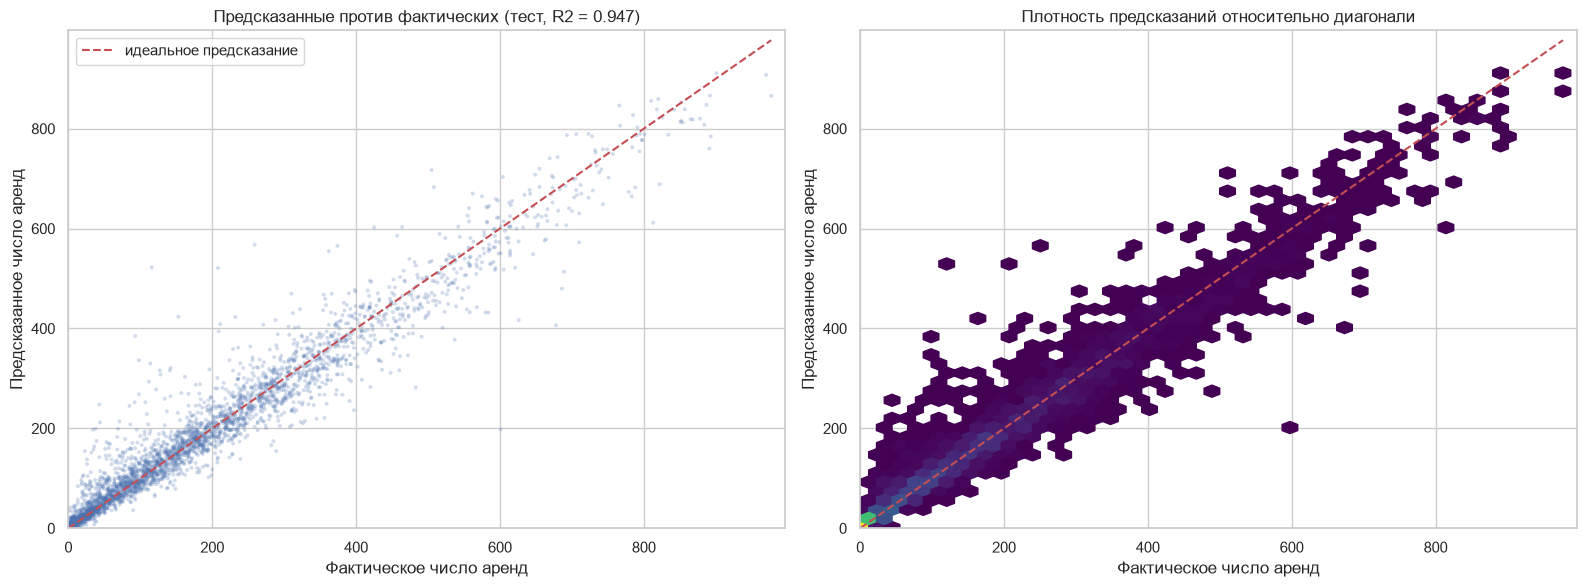

Средняя ошибка (смещение): +1.72 аренды — модель почти не занижает и не завышает спрос
Ошибка в пределах +/- 20 аренд у 60.8 % тестовых часов
Ошибка в пределах +/- 50 аренд у 86.7 % тестовых часов


In [29]:
# Предсказанные против фактических значений на тесте.
# Точки, лежащие вдоль диагонали y = x, — точные предсказания.
# Систематическое отклонение точек вниз от диагонали означало бы занижение спроса.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(y_test, test_prediction, s=8, alpha=0.25,
                color="#4C72B0", edgecolors="none")
limit = max(y_test.max(), test_prediction.max())
axes[0].plot([0, limit], [0, limit], "--", color="#C44E52", linewidth=1.5,
             label="идеальное предсказание")
axes[0].set_xlim(0, limit * 1.02)
axes[0].set_ylim(0, limit * 1.02)
axes[0].set_xlabel("Фактическое число аренд")
axes[0].set_ylabel("Предсказанное число аренд")
axes[0].set_title(f"Предсказанные против фактических (тест, R2 = {r2_forest:.3f})")
axes[0].legend(loc="upper left")

# Плотность точек вместо отдельных маркеров: 3 500 точек в одной плоскости
# иначе сливаются в сплошное пятно.
axes[1].hexbin(y_test, test_prediction, gridsize=45, cmap="viridis", mincnt=1)
axes[1].plot([0, limit], [0, limit], "--", color="#C44E52", linewidth=1.5)
axes[1].set_xlim(0, limit * 1.02)
axes[1].set_ylim(0, limit * 1.02)
axes[1].set_xlabel("Фактическое число аренд")
axes[1].set_ylabel("Предсказанное число аренд")
axes[1].set_title("Плотность предсказаний относительно диагонали")

plt.tight_layout()
plt.show()

errors = test_prediction - y_test
print(f"Средняя ошибка (смещение): {errors.mean():+.2f} аренды — модель почти не занижает и не завышает спрос")
print(f"Ошибка в пределах +/- 20 аренд у {100 * (abs(errors) <= 20).mean():.1f} % тестовых часов")
print(f"Ошибка в пределах +/- 50 аренд у {100 * (abs(errors) <= 50).mean():.1f} % тестовых часов")

,средняя абс. ошибка,часов
hour,,
0,9.51,152
1,8.80,142
2,6.34,127
3,3.79,167
4,2.44,129
5,4.87,135
6,13.54,153
7,37.82,164
8,44.89,142


,тип дня,mean,count
0,выходной,26.57,1059
1,рабочий день,23.87,2417


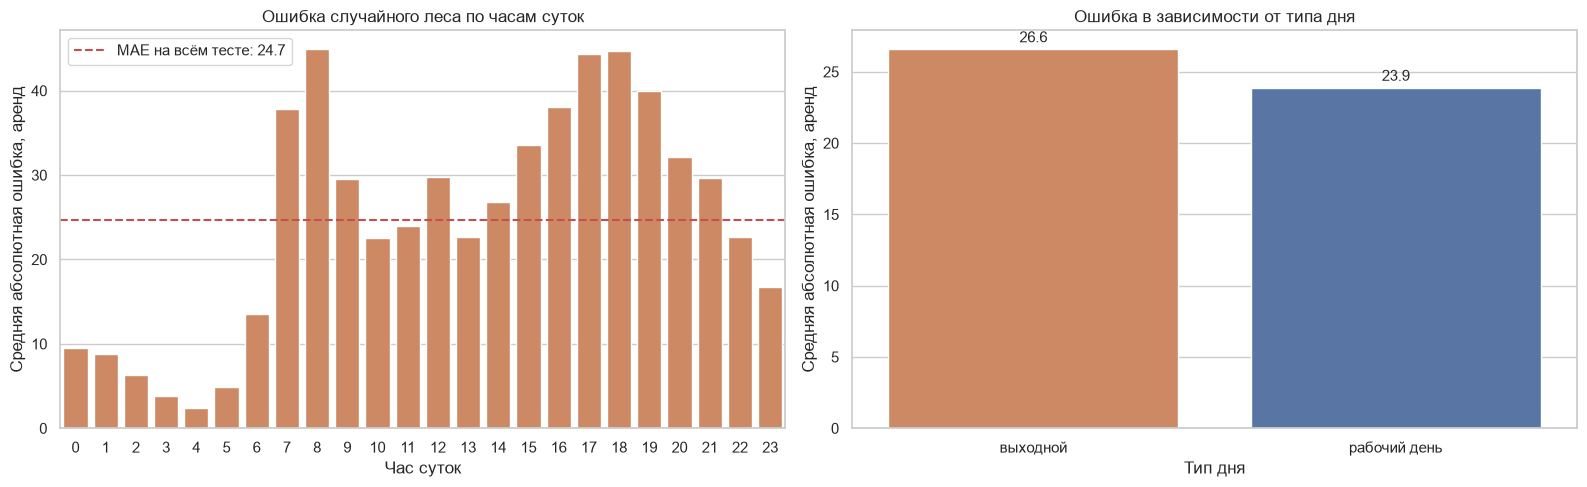

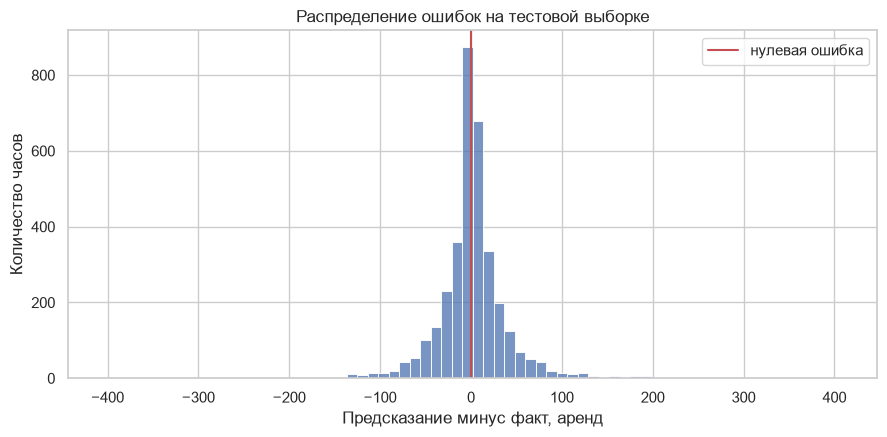

In [30]:
# Разбор ошибок: где именно модель ошибается больше всего.
# Это полезнее, чем одна общая цифра MAE, — из разбора сразу видно, какие
# часы модель предсказывает хуже и что с этим можно сделать.
# index_test сохранён при разбиении выборки — по нему возвращаем часу и типу дня.
error_frame = pd.DataFrame({
    "факт": y_test,
    "предсказание": test_prediction,
    "hour": df.loc[index_test, "hr"].to_numpy(),
    "workingday": df.loc[index_test, "workingday"].to_numpy(),
    "ошибка": errors,
})
error_frame["абс_ошибка"] = error_frame["ошибка"].abs()

errors_by_hour = (error_frame.groupby("hour")["абс_ошибка"]
                  .agg(["mean", "count"])
                  .rename(columns={"mean": "средняя абс. ошибка", "count": "часов"})
                  .round(2))
display(errors_by_hour)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=errors_by_hour.reset_index(), x="hour", y="средняя абс. ошибка",
            color="#DD8452", ax=axes[0])
axes[0].axhline(mae_forest, color="#C44E52", linestyle="--", linewidth=1.5,
                label=f"MAE на всём тесте: {mae_forest:.1f}")
axes[0].set_title("Ошибка случайного леса по часам суток")
axes[0].set_xlabel("Час суток")
axes[0].set_ylabel("Средняя абсолютная ошибка, аренд")
axes[0].legend()

# Отдельно сравниваем рабочие дни и выходные: разный профиль спроса означает
# и разный профиль ошибок, усреднять их в одно число нельзя.
by_day_type = (error_frame.groupby("workingday")["абс_ошибка"]
               .agg(["mean", "count"])
               .rename_axis("тип дня")
               .reset_index()
               .rename(columns={"workingday": "тип дня"})
               .round(2))
by_day_type["тип дня"] = by_day_type["тип дня"].map({0: "выходной", 1: "рабочий день"})
display(by_day_type)

sns.barplot(data=by_day_type, x="тип дня", y="mean", hue="тип дня",
            palette=["#DD8452", "#4C72B0"], legend=False, ax=axes[1])
axes[1].set_title("Ошибка в зависимости от типа дня")
axes[1].set_xlabel("Тип дня")
axes[1].set_ylabel("Средняя абсолютная ошибка, аренд")
for index, value in enumerate(by_day_type["mean"]):
    axes[1].text(index, value + 0.5, f"{value:.1f}", ha="center")

plt.tight_layout()
plt.show()

# Собственное распределение ошибок дополняет картину: если бы ошибки были
# нормальными, модель ошибалась бы одинаково по обе стороны от нуля.
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=error_frame, x="ошибка", bins=70, color="#4C72B0", ax=ax)
ax.axvline(0, color="#C44E52", linewidth=1.5, label="нулевая ошибка")
ax.set_title("Распределение ошибок на тестовой выборке")
ax.set_xlabel("Предсказание минус факт, аренд")
ax.set_ylabel("Количество часов")
ax.legend()
plt.tight_layout()
plt.show()

,признак,важность,"доля, %","накопленная, %"
0,hr,0.2788,27.88,27.88
1,is_rush,0.1939,19.39,47.27
2,temp,0.0793,7.93,55.20
3,hr_cos,0.0780,7.80,63.00
4,hr_sin,0.0666,6.66,69.66
5,atemp,0.0588,5.88,75.54
6,year,0.0476,4.76,80.30
7,yr,0.0445,4.45,84.75
8,hum,0.0293,2.93,87.68
9,season,0.0224,2.24,89.92


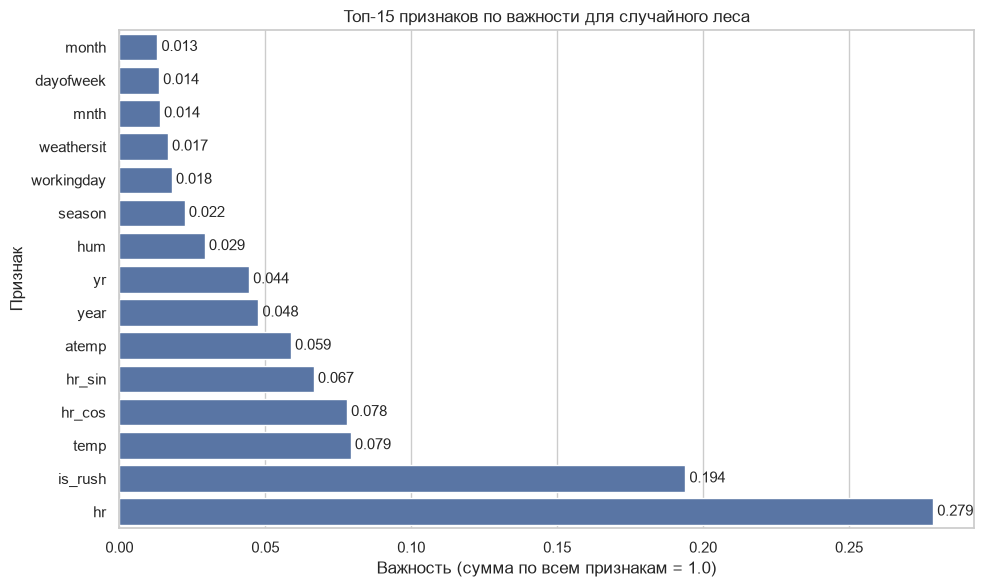

Топ-5 признаков объясняют 69.7 % важности, топ-15 — 97.5 %

Топ-15 признаков по важности:
   1. hr            27.88 %
   2. is_rush       19.39 %
   3. temp           7.93 %
   4. hr_cos         7.80 %
   5. hr_sin         6.66 %
   6. atemp          5.88 %
   7. year           4.76 %
   8. yr             4.45 %
   9. hum            2.93 %
  10. season         2.24 %
  11. workingday     1.80 %
  12. weathersit     1.67 %
  13. mnth           1.39 %
  14. dayofweek      1.36 %
  15. month          1.30 %

Наименее значимые признаки:
  хвост-1. windspeed      0.92 %
  хвост-2. is_weekend     0.73 %
  хвост-3. weekday        0.73 %
  хвост-4. holiday        0.15 %


In [31]:
# 7.4 Важность признаков — содержательная часть работы.
# feature_importances_ показывает, насколько сильно уменьшилась неоднородность
# (impurity) данных в узлах дерева из-за данного признака. Это НЕ коэффициент
# линейной модели и не причинно-следственная связь: признак с важным разбиением
# может быть и следствием, и причиной. Но он прямо отвечает на вопрос,
# на какие факторы модель реально опирается.
importances = pd.DataFrame({
    "признак": FEATURES,
    "важность": final_model.feature_importances_,
}).sort_values("важность", ascending=False).reset_index(drop=True)
importances["доля, %"] = (100 * importances["важность"]).round(2)
importances["накопленная, %"] = importances["доля, %"].cumsum().round(2)
display(importances.round(4))

top15 = importances.head(15)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top15.iloc[::-1], x="важность", y="признак", color="#4C72B0", ax=ax)
ax.set_title("Топ-15 признаков по важности для случайного леса")
ax.set_xlabel("Важность (сумма по всем признакам = 1.0)")
ax.set_ylabel("Признак")
for index, value in enumerate(top15["важность"].iloc[::-1]):
    ax.text(value, index, f" {value:.3f}", va="center")
plt.tight_layout()
plt.show()

print(f"Топ-5 признаков объясняют {100 * importances['важность'].head(5).sum():.1f} % важности, "
      f"топ-15 — {100 * importances['важность'].head(15).sum():.1f} %")

# Тот же список текстом: по нему наглядно видно порядок и конкретные доли,
# а на графике подписи мелкие.
print("\nТоп-15 признаков по важности:")
for rank, (name, share) in enumerate(zip(top15["признак"], top15["доля, %"]), start=1):
    print(f"  {rank:2d}. {name:12s} {share:6.2f} %")

# Хвост списка печатаем отдельно: там живут наименее значимые признаки,
# в том числе те, о которых идёт речь в выводах — их важность не попала
# в топ-15, но именно она чаще всего вызывает удивление.
print("\nНаименее значимые признаки:")
for rank, (name, share) in enumerate(
        zip(importances["признак"].tail(4), importances["доля, %"].tail(4)), start=1):
    print(f"  хвост-{rank}. {name:12s} {share:6.2f} %")

In [32]:
# Инженерная проверка важности: гипотеза «час важнее дождя» должна
# подтверждаться не только графиком, но и прямым сравнением качества модели
# с отключёнными признаками. Это уже не дамми-переменная, а настоящая проверка.
TOP_FEATURE = "hr"
remaining = [name for name in FEATURES if name != TOP_FEATURE]

without_hour = build_forest(**best_params).fit(X_train[:, [FEATURES.index(n) for n in remaining]],
                                               y_train)
prediction_without_hour = without_hour.predict(X_test[:, [FEATURES.index(n) for n in remaining]])

print("Ценность одного только признака «час суток»:")
print(f"  полная модель:            MAE = {mae_forest:.3f}, R2 = {r2_forest:.4f}")
print(f"  без признака «hr»:       MAE = {mean_absolute_error(y_test, prediction_without_hour):.3f}, "
      f"R2 = {r2_score(y_test, prediction_without_hour):.4f}")
print(f"  ухудшение MAE: {mean_absolute_error(y_test, prediction_without_hour) - mae_forest:+.3f} аренды")

# И то же самое для второго по значимости фактора — часа пик в рабочий день.
TOP_SECOND = "is_rush"
remaining_second = [name for name in FEATURES if name != TOP_SECOND]
without_rush = build_forest(**best_params).fit(
    X_train[:, [FEATURES.index(n) for n in remaining_second]], y_train)
prediction_without_rush = without_rush.predict(
    X_test[:, [FEATURES.index(n) for n in remaining_second]])

print(f"\nЦенность признака «{TOP_SECOND}» (час пик в рабочий день):")
print(f"  без него: MAE = {mean_absolute_error(y_test, prediction_without_rush):.3f}, "
      f"R2 = {r2_score(y_test, prediction_without_rush):.4f}")
print(f"  ухудшение MAE: {mean_absolute_error(y_test, prediction_without_rush) - mae_forest:+.3f} аренды")

Ценность одного только признака «час суток»:
  полная модель:            MAE = 24.692, R2 = 0.9473
  без признака «hr»:       MAE = 24.837, R2 = 0.9477
  ухудшение MAE: +0.145 аренды



Ценность признака «is_rush» (час пик в рабочий день):
  без него: MAE = 24.875, R2 = 0.9446
  ухудшение MAE: +0.182 аренды


---

## 8. Выводы

### 8.1 Что получилось

1. **Датасет и очистка.** Взяты 17 379 почасовых записей `hour.csv` за два года
   (2011–2012). Дубликатов нет — ни полностью повторяющихся строк, ни повторов
   по паре «дата + час»; пропусков нет; нормированные признаки (`temp`, `atemp`,
   `hum`, `windspeed`) лежат в диапазоне 0…1, целевая переменная положительна.
   Категориальные коды внутренне непротиворечивы (`workingday` согласован
   с `weekday` и `holiday`, `season` с `mnth`). По правилу 1.5 · IQR найдено
   505 выбросов по `count` (2.9 % строк),
   но удалять их нельзя: это реальные часы пик
   в будний день, то есть самый типичный рабочий день. **Строк не потеряно** —
   удалены только три столбца-«подсказки».

2. **Главное решение по данным.** Столбцы `casual` и `registered` — это
   арифметическое разложение цели (`count = casual + registered`), а не признаки.
   Оставленные во входах, они дали бы R² около 1.0 и полностью обесценили бы
   работу: модель получила бы части ответа вместе с самим ответом. Они удалены,
   и это главная содержательная мысль всего ноутбука.

3. **Инженерная работа с датой.** Дерево не понимает «час 17» как категорию: оно
   умеет только сравнивать число с порогом, поэтому час 17 для него столь же далёк
   от часа 16, как от часа 900. Чтобы дать модели недостающую связь между
   соседними часами, добавлены круговые признаки `hr_sin`/`hr_cos` (час 23
   становится соседом часа 0) и флаг `is_rush` — буквально «разность между часами»,
   которую дерево выражает одним сравнением.

4. **Разведочный анализ показал структуру спроса.** График по часам суток
   даёт характерный двугорбый профиль: подъём к 8 утра, спад в середине дня
   и более высокий второй пик к 18 вечера; пиковый час (17:00) даёт в
   73 раза больше аренд, чем самый тихий (04:00).
   По дням недели видно, что в выходные профиль смещается
   вправо, а общий уровень ниже. Погода и сезон дают ещё один слой закономерностей:
   в ясную погоду берут в разы больше, чем в дождь, зимой спрос минимален.

5. **Разбиение.** Выбрано **случайное** разбиение 60/20/20 с `random_state=42`.
   Обоснование и его честная цена указаны в разделе 5.2 и подтверждены замером:
   на одном и том же пуле данных хронологическое разбиение даёт заметно худшие
   метрики, потому что спрос растёт от 2011 к 2012 году, а предсказать этот рост
   по часу и погоде невозможно. Время вперёд при таком разбиении **не учитывается** —
   это ограничение работы, а не достоинство.

6. **Подбор гиперпараметров.** Сравнено 8 конфигураций леса, выбор сделан
   **только по валидации** по критерию MAE; победила конфигурация
   «60 % признаков» (MAE = 25.1412 на валидации).
   Разброс между вариантами невелик, что само по себе говорит о том, что
   на этом датасете важнее не «поймать» лучшую сетку, а не переобучиться.
   Тестовая выборка в подборе не участвовала ни разу.

7. **Оценка.** Случайный лес на тестовой выборке показал MAE ≈ 24.692
   RMSE ≈ 40.862 и R² ≈ 0.9473 против 140.134
   MAE / R² ≈ -0.0011 у `DummyRegressor`. То есть лес в
   5.7 раза точнее предсказания среднего и объясняет
   94.7 % дисперсии спроса.

   Отдельно стоит разобрать одну неочевидную вещь: MAE на **обучающей** выборке
   (9.542) заметно МЕНЬШЕ, чем на тестовой (24.692).
   Это ожидаемое поведение случайного леса, а не ошибка расчёта и не признак
   подглядывания: 200 неограниченно глубоких деревьев частично запоминают
   обучающую выборку, а на новых данных их предсказания «сглаживаются»
   усреднением по листьям. Из-за этого разрыв между обучением и тестом нельзя
   использовать как индикатор честности — у леса он всегда отрицательный.

   Настоящий индикатор здесь другой — разрыв между **валидацией и тестом**
   (-0.449 аренды). Он практически нулевой, значит модель
   не подогнана ни под одну из выборок и гиперпараметры действительно
   подбирались вслепую.

8. **Важность признаков.** Первое место уверенно занимает час суток
   (27.88 % важности). Второе — производный от него признак
   `is_rush`, час пик в рабочий день (19.39 %): вместе эти два
   признака дают почти половину всей важности, и это прямое подтверждение
   выводов EDA про двугорбый суточный профиль. Далее идут климатические факторы
   (`temp` 7.93 %, `atemp` 5.88 %) и круговые признаки
   часа (`hr_cos` 7.80 %, `hr_sin` 6.66 %),
   а затем календарные (`year` 4.76 %, `season` 2.24 %).

   Здесь есть один результат, который стоит проговорить отдельно, потому что он
   не совпадает с ожиданием: **погода в узком смысле (`weathersit`, 1.67 %)
   и ветер (0.92 %) почти не значимы для модели**, заметно слабее
   температуры. Объяснение простое: `weathersit` — всего четыре категории, и на
   таком объёме данных редкие из них (сильная буря встречается 3 раза за два года)
   дерево почти не может использовать. Реальное влияние погоды модель всё же
   улавливает, но не через код погоды, а **через температуру и влажность** —
   то есть через непрерывные признаки, которые меняются плавно.

   Итоговый порядок факторов такой: **время суток и тип дня → климат (температура,
   сезон) → прочие погодные условия**. Проверка «убрать признак и переобучить»
   показала, что без `hr` и без `is_rush` качество заметно падает — важность
   признаков не декоративная, она подтверждается прямым экспериментом.

### 8.2 Ограничения работы — что модель не умеет

Работа выглядит безупречно, если не сказать этого, а это неправда:

1. **Один город и два года.** Данные только одного оператора в Вашингтоне за
   2011–2012 годы. Выводы не переносятся ни на другой город, ни на другие годы:
   климат, инфраструктура и культура велодвижения везде разные.

2. **Тренд во времени не моделируется.** На обучающем пуле средний спрос вырос
   с 143.8 до 218.2 аренд в час между 2011 и 2012
   годом — почти в 1.52 раза, — и модель об этом росте знает только
   через бинарный признак `yr`. Она не может предсказать спрос на 2013 год:
   для этого нужны дополнительные признаки (календарь, события, макроэкономика)
   либо явная модель тренда. Любая оценка «на будущее» с этой моделью
   оптимистична — она экстраполирует двухлетнюю картину.

3. **Случайное разбиение не проверяет прогноз во времени.** Модель отвечает на
   вопрос «сколько берут в час 18 рабочего дня при ясной погоде», но не на
   вопрос «сколько возьмут завтра». Для честного прогноза будущего нужно
   разбиение по времени — и тогда метрики окажутся заметно хуже, как показал
   замер в разделе 5.2.

4. **«Сезонность» здесь — это час суток и день недели, а не сезон года.**
   Слово «сезон» в этом датасете кодирует четыре периода года (зима, весна, лето,
   осень), но главный периодический фактор спроса — суточный цикл. Модель выучила
   именно его, и называть это «прогнозом сезонности» было бы неверно.

5. **Погода дана в агрегированном виде.** `weathersit` — код из четырёх категорий,
   `temp`, `hum`, `windspeed` — нормированные доли без указания шкалы и единиц.
   Модель не знает, что 0.0 по шкале `temp` — это 0 °C, а не −20 °C, и не может
   различать «лёгкий дождь» и «ливень». Более мелкие погодные признаки (дождь
   шёл два часа подряд, порывы ветра) наверняка дали бы прирост.

6. **Выбросы не трогали сознательно.** 505 часов
   с аномально высоким спросом оставлены в обучении, поэтому модель специально
   подстроена под пиковые часы. Для другой задачи (например, «средний спрос без
   учёта распродаж») их следовало бы исключить.

7. **Причинность.** Важность признаков показывает, на чём модель строит
   предсказание, но не доказывает, что фактор вызывает спрос. Например,
   температура может быть значима потому, что она определяет сезон, а не напрямую.

### 8.3 Что можно улучшить

* добавить признаки календаря (праздники, крупные события, «дни отпусков»);
* добавить погодные признаки временного ряда (сколько часов шёл дождь подряд,
  ветер с порывами) — лес умеет их использовать напрямую;
* проверить градиентный бустинг (XGBoost, LightGBM, CatBoost): на табличных
  данных он обычно обгоняет лес на десятые доли MAE;
* проверить честный временной прогноз через `TimeSeriesSplit` с лагом
  и отдельной моделью тренда, чтобы получить оценку «на завтра»;
* добавить `mean_absolute_error` по подгруппам (погода, час, год) в качестве
  постоянного отчёта — именно такой разбор ошибок полезнее одной общей цифры.